# Mumbai Rental Property Data Analysis

## IAAC — AI Methods | Group 3

### Project Overview

This project investigates rental property listings in Mumbai using Python, data cleaning, exploratory data analysis (EDA), and data validation.

Our objectives are to:
- Examine the original dataset and identify data quality issues.
- Clean and preprocess rental property data.
- Explore relationships between rental prices and property characteristics.
- Evaluate data retention, reliability, and potential bias introduced by cleaning.

### Team Contributions

- **Ahmed:** Initial exploration and project development.
- **Nandhini:** Data cleaning and preprocessing.
- **Sanjana:** Exploratory data analysis and visualizations.
- **Akanksha:** Data validation and quality assessment.

### Dataset

**Source:** Kaggle — Property Rental Listings Dataset  
**Author:** harshalhonde  
**File:** `Mumbai_property_details.csv`

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
from pathlib import Path

pd.set_option("display.max_columns", None)

print("All libraries imported successfully.")


All libraries imported successfully.


## 1. Data Loading and Initial Exploration

We begin by loading the original Mumbai rental property dataset to examine its structure, dimensions, data types, and initial quality.

In [2]:
# Download the original dataset from Kaggle
dataset_path = Path(
    kagglehub.dataset_download(
        "harshalhonde/property-rental-listings-dataset"
    )
)

# Load the original CSV
csv_path = dataset_path / "Mumbai_property_details.csv"
df_raw = pd.read_csv(csv_path)

print("Original dataset shape:", df_raw.shape)
display(df_raw.head())

Original dataset shape: (23405, 18)


,Title,Price,Area,BHK,Bathrooms,Furnished,Balconies,Floor,Ownership,Facing,Amenities,Transaction Type,Property Type,Location,Year of Construction,Is Luxury,Description,Property Image
0,1BHK Multistorey Apartment for Rent in Bandra ...,"70,000",750 12800,1,1,Furnished,NaN,7,NaN,South -West,Main Road,Rent,Apartment,Mumbai,2012.0,F,"1 BHK, Multistorey Apartment is available for ...",67249079_2_PropertyImage345-4855396928822.jpg
1,3BHK Multistorey Apartment for Rent in Lodha N...,1.4 Lac,1980 12800,3,4,Unfurnished,4,21,NaN,East,"Garden/Park, Pool, Main Road",Rent,Apartment,Mumbai,1994.0,F,"3 BHK, Multistorey Apartment is available for ...",66155783_5_hatsAppImage20230217at13.56.28.jpeg
2,3BHK Multistorey Apartment for Rent in Lodha P...,1.9 Lac,1592 12800,3,3,Unfurnished,1,20,NaN,North - East,Main Road,Rent,Apartment,Mumbai,NaN,F,"3 BHK, Multistorey Apartment is available for ...",66686709_1_HOTO20230407165614.jpg
3,3BHK Multistorey Apartment for Rent in Rustomj...,1.1 Lac,1305 12800,3,3,Unfurnished,3,11,Freehold,West,"Garden/Park, Main Road",Rent,Apartment,Mumbai,2010.0,F,"3 BHK, Multistorey Apartment is available for ...",67875387_1_PropertyImage559-8385323621333.jpg
4,3BHK Multistorey Apartment for Rent in DLH The...,1.4 Lac,1350 12800,3,3,Unfurnished,NaN,29,Freehold,East,"Pool, Garden/Park, Main Road",Rent,Apartment,Mumbai,2000.0,F,"3 BHK, Multistorey Apartment is available for ...",66670931_3_PropertyImage314-6685675359874.jpg


### 1.1 Initial Data Quality Assessment

This section provides a concise overview of the original dataset, including its dimensions, missing values, duplicate records, and column data types.

The objective is to establish a baseline for evaluating the impact of subsequent cleaning operations.

In [3]:
# Initial data quality assessment

quality_report = pd.DataFrame({
    "Data Type": df_raw.dtypes.astype(str),
    "Missing Values": df_raw.isna().sum(),
    "Missing (%)": (df_raw.isna().mean() * 100).round(2),
    "Unique Values": df_raw.nunique(dropna=True)
})

print(f"Original records: {len(df_raw):,}")
print(f"Total columns: {df_raw.shape[1]}")
print(f"Duplicate records: {df_raw.duplicated().sum():,}")

display(quality_report)

Original records: 23,405
Total columns: 18
Duplicate records: 3,111


,Data Type,Missing Values,Missing (%),Unique Values
Title,str,0,0.00,7035
Price,str,2,0.01,477
Area,str,0,0.00,1381
BHK,str,411,1.76,8
Bathrooms,str,204,0.87,11
Furnished,str,189,0.81,3
Balconies,str,13017,55.62,11
Floor,str,1120,4.79,80
Ownership,str,20570,87.89,4
Facing,str,4281,18.29,8


## 2. Data Cleaning and Preprocessing

This section consolidates the data cleaning work conducted by the team.

The objective is to improve data quality while preserving as much relevant information as possible.

The cleaning workflow focuses on:
- Handling missing and inconsistent values.
- Standardizing numerical and categorical attributes.
- Identifying duplicate and invalid records.
- Evaluating the impact of cleaning on dataset retention.

We use the team's existing cleaned dataset as a reference and document the transformations applied.

In [4]:
# Locate the project root
project_root = Path.cwd()

if not (project_root / "data").exists():
    project_root = project_root.parent

# Load the team's cleaned dataset
cleaned_path = (
    project_root / "data" / "cleaned"
    / "mumbai_rentals_cleaned.csv"
)

df_clean = pd.read_csv(cleaned_path)

print("Original dataset:", df_raw.shape)
print("Cleaned dataset:", df_clean.shape)

display(df_clean.head())

Original dataset: (23405, 18)
Cleaned dataset: (20181, 20)


,Title,Price,Area,BHK,Bathrooms,Furnished,Balconies,Floor,Ownership,Facing,Amenities,Transaction Type,Property Type,Location,Year of Construction,Is Luxury,Description,Property Image,Price_per_m2,Suspicious_Price
0,1BHK Multistorey Apartment for Rent in Bandra ...,70000.0,750.0,1.0,1.0,Furnished,NaN,7.0,Unknown,South -West,Main Road,Rent,Apartment,Mumbai,2012.0,F,"1 BHK, Multistorey Apartment is available for ...",67249079_2_PropertyImage345-4855396928822.jpg,93.333333,False
1,3BHK Multistorey Apartment for Rent in Lodha N...,140000.0,1980.0,3.0,4.0,Unfurnished,4.0,21.0,Unknown,East,"Garden/Park, Pool, Main Road",Rent,Apartment,Mumbai,1994.0,F,"3 BHK, Multistorey Apartment is available for ...",66155783_5_hatsAppImage20230217at13.56.28.jpeg,70.707071,False
2,3BHK Multistorey Apartment for Rent in Lodha P...,190000.0,1592.0,3.0,3.0,Unfurnished,1.0,20.0,Unknown,North - East,Main Road,Rent,Apartment,Mumbai,NaN,F,"3 BHK, Multistorey Apartment is available for ...",66686709_1_HOTO20230407165614.jpg,119.346734,False
3,3BHK Multistorey Apartment for Rent in Rustomj...,110000.0,1305.0,3.0,3.0,Unfurnished,3.0,11.0,Freehold,West,"Garden/Park, Main Road",Rent,Apartment,Mumbai,2010.0,F,"3 BHK, Multistorey Apartment is available for ...",67875387_1_PropertyImage559-8385323621333.jpg,84.291188,False
4,3BHK Multistorey Apartment for Rent in DLH The...,140000.0,1350.0,3.0,3.0,Unfurnished,NaN,29.0,Freehold,East,"Pool, Garden/Park, Main Road",Rent,Apartment,Mumbai,2000.0,F,"3 BHK, Multistorey Apartment is available for ...",66670931_3_PropertyImage314-6685675359874.jpg,103.703704,False


In [5]:
# Dataset retention summary

original_rows = len(df_raw)
cleaned_rows = len(df_clean)

rows_removed = original_rows - cleaned_rows
retention_rate = cleaned_rows / original_rows * 100

summary = pd.DataFrame({
    "Metric": [
        "Original Records",
        "Cleaned Records",
        "Records Removed",
        "Retention Rate (%)"
    ],
    "Value": [
        original_rows,
        cleaned_rows,
        rows_removed,
        round(retention_rate, 2)
    ]
})

display(summary)

,Metric,Value
0,Original Records,23405.00
1,Cleaned Records,20181.00
2,Records Removed,3224.00
3,Retention Rate (%),86.23


### 2.2 Identification of Potentially Unreliable Records

We identify records with missing, invalid, or potentially implausible numerical values.

The objective is to distinguish genuine data quality issues from legitimate extreme observations before applying additional filtering.

In [6]:
# Inspect numerical fields before additional filtering

fields = ["Price", "Area", "BHK", "Bathrooms", "Balconies"]

numeric_data = pd.DataFrame(index=df_clean.index)

for col in fields:
    numeric_data[col] = pd.to_numeric(
        df_clean[col].astype("string").str.replace(
            r"[^\d.\-]", "", regex=True
        ),
        errors="coerce"
    )

diagnostic = pd.DataFrame({
    "Missing or Non-numeric": numeric_data.isna().sum(),
    "Zero or Negative": (numeric_data <= 0).sum(),
    "Minimum": numeric_data.min(),
    "Median": numeric_data.median(),
    "99th Percentile": numeric_data.quantile(0.99),
    "Maximum": numeric_data.max()
})

display(diagnostic)

,Missing or Non-numeric,Zero or Negative,Minimum,Median,99th Percentile,Maximum
Price,0,0,1800.0,70000.0,700000.0,4000000.0
Area,629,0,50.0,1080.5,4436.0,15000.0
BHK,187,0,1.0,2.0,5.0,7.0
Bathrooms,33,0,1.0,2.0,5.0,10.0
Balconies,10947,0,1.0,2.0,5.0,10.0


In [7]:
# Inspect potentially extreme property records

extreme_cases = df_clean.loc[
    (numeric_data["Price"] > numeric_data["Price"].quantile(0.99))
    | (numeric_data["Area"] > numeric_data["Area"].quantile(0.99))
    | (numeric_data["Bathrooms"] > 6)
    | (numeric_data["Balconies"] > 6)
].copy()

print("Potentially extreme records:", len(extreme_cases))

columns_to_show = [
    "Title", "Price", "Area", "BHK",
    "Bathrooms", "Balconies", "Property Type"
]

display(
    extreme_cases[columns_to_show].head(20)
)


Potentially extreme records: 288


,Title,Price,Area,BHK,Bathrooms,Balconies,Property Type
23,7BHK Multistorey Apartment for Rent in Lodha W...,1300000.0,3800.0,7.0,5.0,4.0,Apartment
30,5BHK Multistorey Apartment for Rent in Windsor...,750000.0,6600.0,5.0,6.0,5.0,Apartment
36,5BHK Multistorey Apartment for Rent in Lodha W...,750000.0,6173.0,5.0,8.0,2.0,Apartment
56,5BHK Multistorey Apartment for Rent in Hiranan...,500000.0,13000.0,5.0,5.0,1.0,Apartment
116,4BHK Multistorey Apartment for Rent in The Imp...,1200000.0,4500.0,4.0,5.0,5.0,Apartment
136,4BHK Multistorey Apartment for Rent in Platinu...,450000.0,4500.0,4.0,4.0,NaN,Apartment
182,5BHK Multistorey Apartment for Rent in Bandra ...,1000000.0,4000.0,5.0,5.0,NaN,Apartment
264,4BHK Multistorey Apartment for Rent in Wadhwa ...,500000.0,5113.0,4.0,6.0,1.0,Apartment
298,4BHK Multistorey Apartment for Rent in Finessi...,310000.0,5500.0,4.0,5.0,1.0,Apartment
319,5BHK Multistorey Apartment for Rent in Hiranan...,500000.0,4575.0,5.0,6.0,2.0,Apartment


In [8]:
# Assess unusual property configurations

flags = pd.DataFrame(index=df_clean.index)

flags["BHK above 5"] = numeric_data["BHK"] > 5
flags["Bathrooms above 6"] = numeric_data["Bathrooms"] > 6
flags["Balconies above 5"] = numeric_data["Balconies"] > 5

report = pd.DataFrame({
    "Criterion": flags.columns,
    "Flagged Records": flags.sum().values
})

display(report)

any_flag = flags.any(axis=1)

print("Total unique flagged records:", any_flag.sum())
print("Records remaining if excluded:", (~any_flag).sum())


,Criterion,Flagged Records
0,BHK above 5,43
1,Bathrooms above 6,28
2,Balconies above 5,34


Total unique flagged records: 90
Records remaining if excluded: 20091


In [10]:
# Domain-informed filtering — preserve missing values

invalid_config = (
    (numeric_data["BHK"] > 5).fillna(False)
    | (numeric_data["Bathrooms"] > 6).fillna(False)
    | (numeric_data["Balconies"] > 5).fillna(False)
)

# Rebuild directly from the original cleaned dataset
df_analysis = df_clean.loc[~invalid_config].copy()

before = len(df_clean)
excluded = int(invalid_config.sum())
after = len(df_analysis)

print("Records before filtering:", before)
print("Records excluded:", excluded)
print("Records after filtering:", after)
print("Retention rate (%):", round(after / before * 100, 2))

assert before - excluded == after, "Filtering count mismatch"


Records before filtering: 20181
Records excluded: 90
Records after filtering: 20091
Retention rate (%): 99.55


### 2.3 Domain-Informed Quality Filtering

Additional filtering criteria were informed by local knowledge of Mumbai's residential rental market.

Properties reporting more than five bedrooms (BHK), six bathrooms, or five balconies were excluded from the analytical sample as potentially unreliable or outside the scope of conventional residential properties.

These thresholds are project-specific assumptions rather than universal validity rules.

The number of excluded records is documented to ensure transparency and reproducibility.

In [11]:
# Analyze rent relative to property size

df_analysis["Price_num"] = numeric_data.loc[
    df_analysis.index, "Price"
]

df_analysis["Area_num"] = numeric_data.loc[
    df_analysis.index, "Area"
]

df_analysis["BHK_num"] = numeric_data.loc[
    df_analysis.index, "BHK"
]

# Calculate rent per unit of area
df_analysis["Rent_per_Area"] = (
    df_analysis["Price_num"] / df_analysis["Area_num"]
)

# Only use valid positive values for the diagnostic
valid = df_analysis.loc[
    (df_analysis["Price_num"] > 0)
    & (df_analysis["Area_num"] > 0)
].copy()

# Compare properties within BHK groups
bhk_summary = valid.groupby("BHK_num").agg(
    Properties=("Price_num", "size"),
    Median_Rent=("Price_num", "median"),
    Median_Area=("Area_num", "median"),
    Median_Rent_per_Area=("Rent_per_Area", "median")
).round(2)

display(bhk_summary)

,Properties,Median_Rent,Median_Area,Median_Rent_per_Area
BHK_num,,,,
1.0,4441,35000.0,600.0,58.33
2.0,7979,65000.0,1000.0,62.5
3.0,5291,130000.0,1550.0,80.0
4.0,1386,280000.0,2600.0,106.82
5.0,188,450000.0,3775.0,111.27


In [13]:
# Identify potential rent-per-area outliers within each BHK group

valid = df_analysis.loc[
    (df_analysis["Price_num"] > 0)
    & (df_analysis["Area_num"] > 0)
    & (df_analysis["BHK_num"].notna())
].copy()

valid["Rent_per_Area"] = (
    valid["Price_num"] / valid["Area_num"]
)

# Calculate the 99th percentile within each BHK group
valid["Group_P99"] = valid.groupby("BHK_num")[
    "Rent_per_Area"
].transform(lambda x: x.quantile(0.99))

valid["Potential_Outlier"] = (
    valid["Rent_per_Area"] > valid["Group_P99"]
)

outlier_report = valid.groupby("BHK_num").agg(
    Total_Properties=("Price_num", "size"),
    Potential_Outliers=("Potential_Outlier", "sum")
)

outlier_report["Outlier_Percentage"] = (
    outlier_report["Potential_Outliers"]
    / outlier_report["Total_Properties"] * 100
).round(2)

display(outlier_report)


,Total_Properties,Potential_Outliers,Outlier_Percentage
BHK_num,,,
1.0,4441,44,0.99
2.0,7979,80,1.0
3.0,5291,53,1.0
4.0,1386,14,1.01
5.0,188,1,0.53


In [14]:
# Create the final analytical sample for visualization

# Keep valid properties, excluding extreme rent-per-area observations
df_final = valid.loc[
    ~valid["Potential_Outlier"]
].copy()

# Final filtering summary
final_report = pd.DataFrame({
    "Metric": [
        "Cleaned dataset",
        "Domain-filtered dataset",
        "Valid Price / Area / BHK records",
        "Extreme observations excluded",
        "Final analytical sample"
    ],
    "Records": [
        len(df_clean),
        len(df_analysis),
        len(valid),
        int(valid["Potential_Outlier"].sum()),
        len(df_final)
    ]
})

display(final_report)

assert len(df_final) == (
    len(valid) - valid["Potential_Outlier"].sum()
)

,Metric,Records
0,Cleaned dataset,20181
1,Domain-filtered dataset,20091
2,Valid Price / Area / BHK records,19285
3,Extreme observations excluded,192
4,Final analytical sample,19093


## 3. Data Quality Improvement and Analytical Filtering

The dataset is refined using domain-informed quality rules and statistical diagnostics.

The objectives are to:
- Exclude implausible property configurations.
- Remove records with unusable price, area, or bedroom information from the core analytical sample.
- Identify extreme rent-per-area observations.
- Document data loss and potential selection bias.
- Compare the dataset before and after filtering.

The filtered dataset is intended for conventional residential rental analysis, rather than representing every segment of Mumbai's rental market.


In [15]:
# Rebuild a consistent analytical dataset

df_work = df_clean.copy()

# Use the numeric columns already inspected
for col in ["Price", "Area", "BHK", "Bathrooms", "Balconies"]:
    df_work[col + "_num"] = numeric_data[col]

# Define documented filtering rules
invalid_price = (
    df_work["Price_num"].isna()
    | (df_work["Price_num"] <= 0)
)

invalid_area = (
    df_work["Area_num"].isna()
    | (df_work["Area_num"] <= 0)
)

invalid_bhk = (
    df_work["BHK_num"].isna()
    | (df_work["BHK_num"] < 1)
    | (df_work["BHK_num"] > 5)
)

invalid_bathrooms = (
    (df_work["Bathrooms_num"] < 1)
    | (df_work["Bathrooms_num"] > 6)
)

invalid_balconies = df_work["Balconies_num"] > 5

# Exclude records failing any core criterion
invalid_records = (
    invalid_price
    | invalid_area
    | invalid_bhk
    | invalid_bathrooms
    | invalid_balconies
).fillna(False)

df_final = df_work.loc[~invalid_records].copy()

print("Before filtering:", len(df_work))
print("Removed records:", int(invalid_records.sum()))
print("After filtering:", len(df_final))
print("Retention (%):", round(
    len(df_final) / len(df_work) * 100, 2
))


Before filtering: 20181
Removed records: 896
After filtering: 19285
Retention (%): 95.56


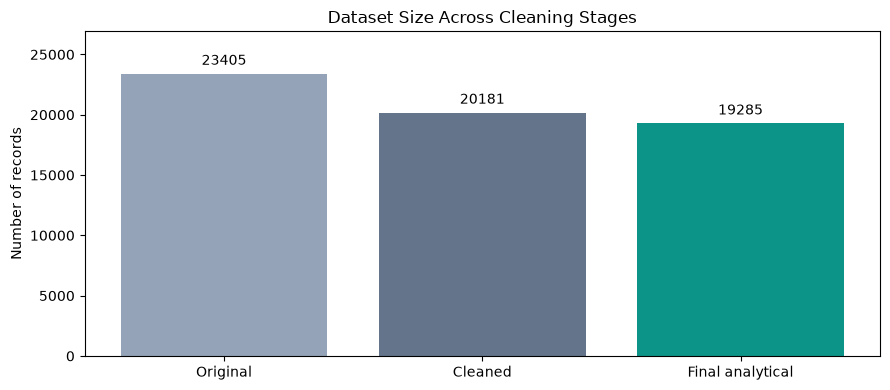

In [16]:
# Visual comparison of dataset retention

stages = ["Original", "Cleaned", "Final analytical"]
counts = [len(df_raw), len(df_clean), len(df_final)]

fig, ax = plt.subplots(figsize=(9, 4))

bars = ax.bar(
    stages,
    counts,
    color=["#94a3b8", "#64748b", "#0d9488"]
)

ax.bar_label(bars, padding=4, fmt="%.0f")
ax.set_ylabel("Number of records")
ax.set_title("Dataset Size Across Cleaning Stages")
ax.set_ylim(0, max(counts) * 1.15)

plt.tight_layout()
plt.show()


,Filtering criterion,Flagged records
0,Invalid or missing price,0
1,Invalid or missing area,629
2,Invalid BHK,230
3,Invalid bathrooms,28
4,Implausible balconies,34


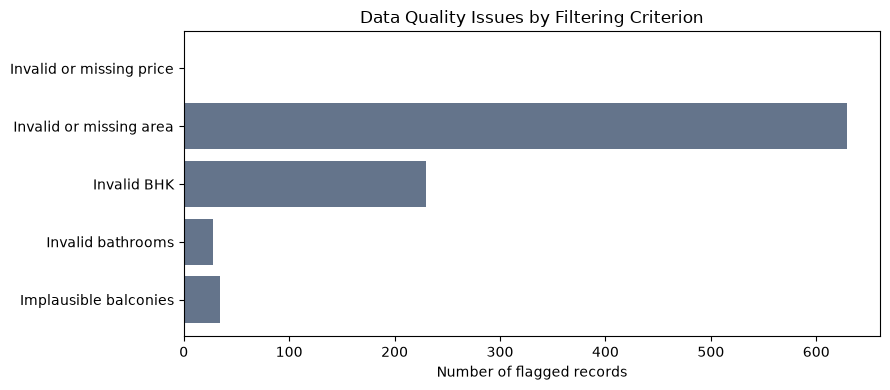

In [17]:
# Audit each filtering criterion

reasons = {
    "Invalid or missing price": invalid_price,
    "Invalid or missing area": invalid_area,
    "Invalid BHK": invalid_bhk,
    "Invalid bathrooms": invalid_bathrooms,
    "Implausible balconies": invalid_balconies
}

audit = pd.DataFrame({
    "Filtering criterion": list(reasons.keys()),
    "Flagged records": [
        int(mask.fillna(False).sum())
        for mask in reasons.values()
    ]
})

display(audit)

fig, ax = plt.subplots(figsize=(9, 4))

ax.barh(
    audit["Filtering criterion"],
    audit["Flagged records"],
    color="#64748b"
)

ax.set_xlabel("Number of flagged records")
ax.set_title("Data Quality Issues by Filtering Criterion")
ax.invert_yaxis()

plt.tight_layout()
plt.show()


## 4. Exploratory Data Analysis

### 4.1 Rental Prices by Property Size (BHK)

This analysis examines how monthly rental prices vary according to the number of bedrooms.

Median rental prices are used to reduce the influence of exceptionally expensive properties.

The objective is to understand whether larger residential units command proportionally higher rents in Mumbai.

,BHK,Properties,Median_Rent
0,1.0,4441,35000.0
1,2.0,7979,65000.0
2,3.0,5291,130000.0
3,4.0,1386,280000.0
4,5.0,188,450000.0


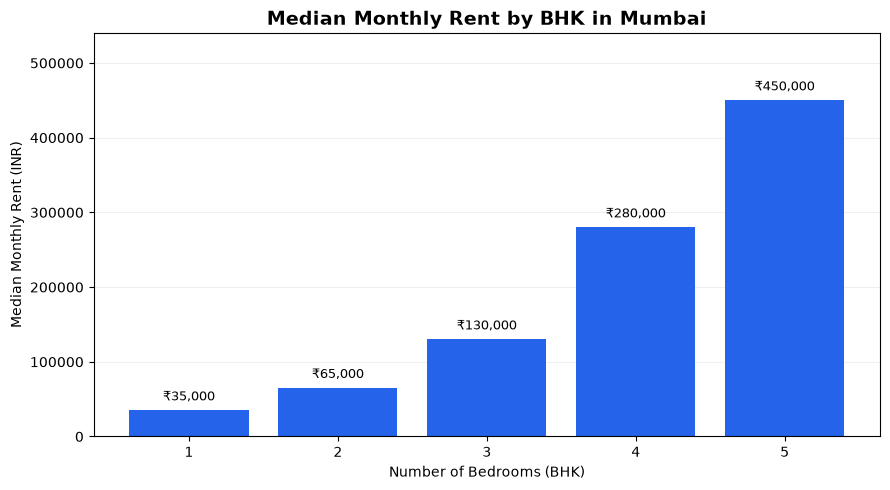

In [18]:
# Median monthly rent by BHK

rent_by_bhk = (
    df_final.groupby("BHK_num")["Price_num"]
    .agg(["count", "median"])
    .reset_index()
    .sort_values("BHK_num")
)

rent_by_bhk.columns = [
    "BHK", "Properties", "Median_Rent"
]

display(rent_by_bhk)

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    rent_by_bhk["BHK"].astype(int).astype(str),
    rent_by_bhk["Median_Rent"],
    color="#2563eb"
)

ax.bar_label(
    bars,
    labels=[
        f"₹{v:,.0f}"
        for v in rent_by_bhk["Median_Rent"]
    ],
    padding=5,
    fontsize=9
)

ax.set_title(
    "Median Monthly Rent by BHK in Mumbai",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Number of Bedrooms (BHK)")
ax.set_ylabel("Median Monthly Rent (INR)")
ax.set_ylim(
    0,
    rent_by_bhk["Median_Rent"].max() * 1.2
)

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


### 4.2 Relationship Between Property Area and Rental Price

This analysis explores the relationship between property area and monthly rent.

Properties are categorized by BHK to identify differences in rental patterns across residential configurations.

The visualization helps assess whether rental prices increase consistently with property size.

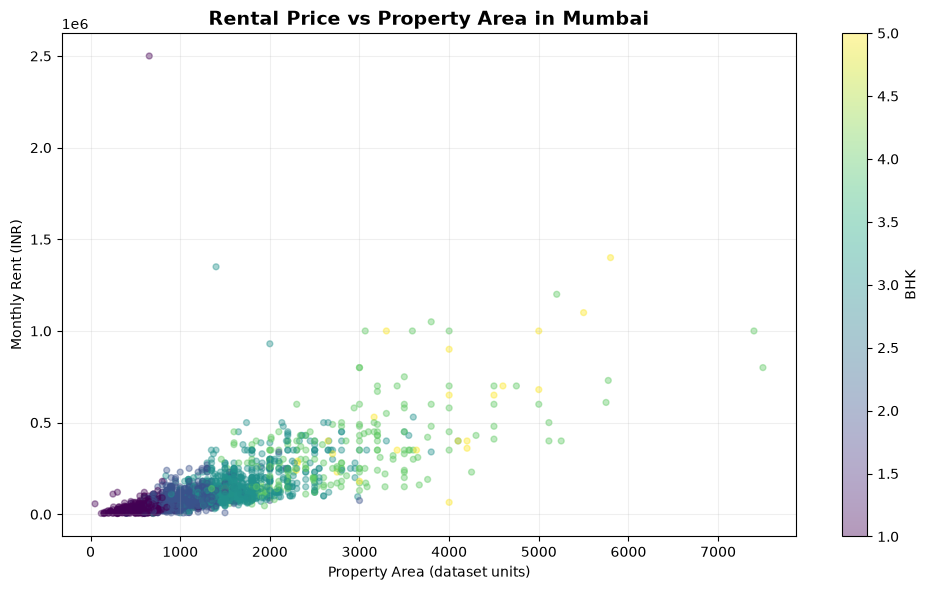

In [19]:
# Relationship between property area and rent

plot_data = df_final[
    ["Area_num", "Price_num", "BHK_num"]
].dropna().copy()

# Sampling is used for visualization only
plot_sample = plot_data.sample(
    n=min(3000, len(plot_data)),
    random_state=42
)

fig, ax = plt.subplots(figsize=(10, 6))

scatter = ax.scatter(
    plot_sample["Area_num"],
    plot_sample["Price_num"],
    c=plot_sample["BHK_num"],
    cmap="viridis",
    alpha=0.4,
    s=18
)

cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("BHK")

ax.set_title(
    "Rental Price vs Property Area in Mumbai",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Property Area (dataset units)")
ax.set_ylabel("Monthly Rent (INR)")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


### 4.3 Investigating Rental Price Anomalies

The scatter plot reveals several unusually expensive rental listings, including properties with high rents relative to their reported area.

To investigate these observations, we calculate rent per unit of area and compare properties within the same BHK category.

Potential anomalies are flagged using the interquartile range (IQR). Flagged observations are reviewed before exclusion, since luxury properties may legitimately have high rental prices.

In [20]:
# Investigate unusual rental prices relative to area

df_review = df_final.copy()

df_review["Rent_per_Area"] = (
    df_review["Price_num"] / df_review["Area_num"]
)

# Calculate outlier thresholds within each BHK group
grouped = df_review.groupby("BHK_num")["Rent_per_Area"]

q1 = grouped.transform(lambda x: x.quantile(0.25))
q3 = grouped.transform(lambda x: x.quantile(0.75))

iqr = q3 - q1

df_review["Upper_Limit"] = q3 + 3 * iqr

# Flag extreme rent-per-area observations
df_review["Potential_Outlier"] = (
    df_review["Rent_per_Area"] >
    df_review["Upper_Limit"]
)

# Review the most extreme listings
review_columns = [
    "Title", "Location", "BHK_num",
    "Area_num", "Price_num",
    "Rent_per_Area"
]

suspect_properties = (
    df_review.loc[
        df_review["Potential_Outlier"],
        review_columns
    ]
    .sort_values("Rent_per_Area", ascending=False)
)

print("Total properties:", len(df_review))
print("Potential outliers:", len(suspect_properties))

display(suspect_properties.head(20))


Total properties: 19285
Potential outliers: 125


,Title,Location,BHK_num,Area_num,Price_num,Rent_per_Area
3149,2BHK Multistorey Apartment for Rent in Nalasop...,Mumbai,2.0,650.0,3800000.0,5846.153846
20174,1BHK Residential House for Rent in Worli,Mumbai,1.0,250.0,1000000.0,4000.0
3148,1BHK Multistorey Apartment for Rent in,Mumbai,1.0,655.0,2500000.0,3816.793893
20163,1BHK Multistorey Apartment for Rent in Seven E...,Mumbai,1.0,557.0,1500000.0,2692.998205
2131,1BHK Multistorey Apartment for Rent in,Mumbai,1.0,466.0,850000.0,1824.034335
20131,2BHK Multistorey Apartment for Rent in Mount Mary,Mumbai,2.0,125.0,160000.0,1280.0
20169,1BHK Multistorey Apartment for Rent in Hiranan...,Mumbai,1.0,50.0,57000.0,1140.0
15731,1BHK Multistorey Apartment for Rent in Godrej ...,Mumbai,1.0,53.0,60000.0,1132.075472
15994,1BHK Multistorey Apartment for Rent in Godrej ...,Mumbai,1.0,53.0,59000.0,1113.207547
2708,2BHK Multistorey Apartment for Rent in Aster a...,Mumbai,2.0,73.0,80000.0,1095.890411


In [21]:
# Inspect extreme rental listings

extreme_listings = (
    df_review.sort_values(
        "Price_num",
        ascending=False
    )
    [review_columns]
    .head(15)
)

display(extreme_listings)

# Number of flagged records by BHK
outliers_by_bhk = (
    df_review.groupby("BHK_num")
    ["Potential_Outlier"]
    .agg(["sum", "count"])
)

outliers_by_bhk["Percentage"] = (
    100 * outliers_by_bhk["sum"]
    / outliers_by_bhk["count"]
)

display(outliers_by_bhk.round(2))


,Title,Location,BHK_num,Area_num,Price_num,Rent_per_Area
3149,2BHK Multistorey Apartment for Rent in Nalasop...,Mumbai,2.0,650.0,3800000.0,5846.153846
10718,5BHK Multistorey Apartment for Rent in Prabhadevi,Mumbai,5.0,14500.0,3000000.0,206.896552
3148,1BHK Multistorey Apartment for Rent in,Mumbai,1.0,655.0,2500000.0,3816.793893
20115,4BHK Multistorey Apartment for Rent in Police ...,Mumbai,4.0,6500.0,1980000.0,304.615385
7902,5BHK Multistorey Apartment for Rent in Beaumon...,Mumbai,5.0,6000.0,1600000.0,266.666667
17963,4BHK Multistorey Apartment for Rent in K Rahej...,Mumbai,4.0,4680.0,1600000.0,341.880342
16704,5BHK Multistorey Apartment for Rent in Navroze...,Mumbai,5.0,6000.0,1500000.0,250.0
711,5BHK Multistorey Apartment for Rent in Sea Bre...,Mumbai,5.0,8000.0,1500000.0,187.5
9287,4BHK Multistorey Apartment for Rent in K Rahej...,Mumbai,4.0,6000.0,1500000.0,250.0
5783,4BHK Multistorey Apartment for Rent in 25 Sout...,Mumbai,4.0,4500.0,1500000.0,333.333333


,sum,count,Percentage
BHK_num,,,
1.0,23,4441,0.52
2.0,88,7979,1.1
3.0,13,5291,0.25
4.0,1,1386,0.07
5.0,0,188,0.0


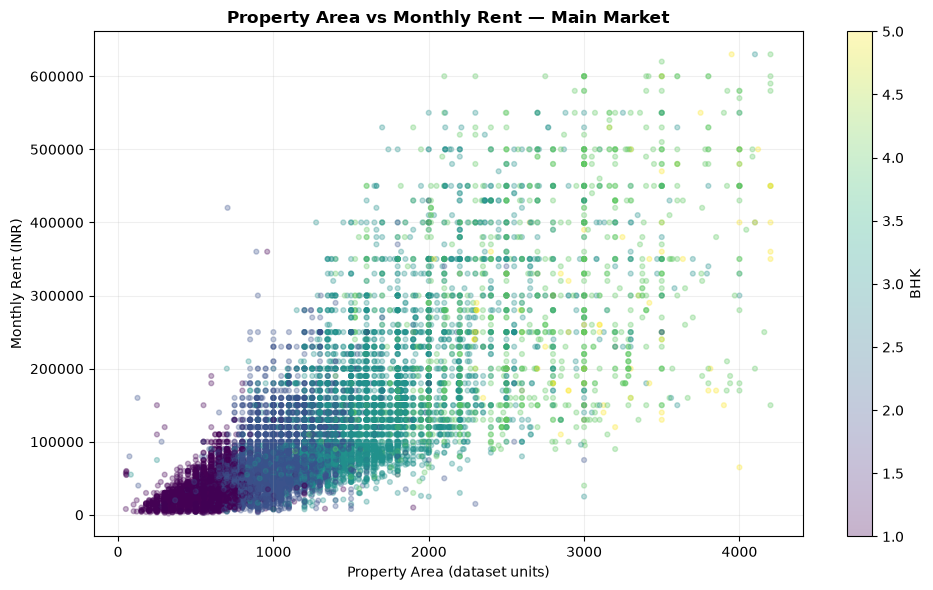

Properties displayed: 19004
Properties in final dataset: 19285


In [22]:
# Focused visualization of the main rental market

price_limit = df_final["Price_num"].quantile(0.99)
area_limit = df_final["Area_num"].quantile(0.99)

df_visual = df_final.loc[
    (df_final["Price_num"] <= price_limit)
    & (df_final["Area_num"] <= area_limit)
].copy()

fig, ax = plt.subplots(figsize=(10, 6))

scatter = ax.scatter(
    df_visual["Area_num"],
    df_visual["Price_num"],
    c=df_visual["BHK_num"],
    cmap="viridis",
    alpha=0.3,
    s=12
)

cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("BHK")

ax.set_title(
    "Property Area vs Monthly Rent — Main Market",
    fontweight="bold"
)

ax.set_xlabel("Property Area (dataset units)")
ax.set_ylabel("Monthly Rent (INR)")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

print("Properties displayed:", len(df_visual))
print("Properties in final dataset:", len(df_final))


In [23]:
# Investigate suspicious property areas

area_review = df_review.copy()

# Flag unusually small properties by BHK
minimum_area = {
    1: 250,
    2: 450,
    3: 650,
    4: 900,
    5: 1200
}

area_review["Minimum_Expected_Area"] = (
    area_review["BHK_num"].map(minimum_area)
)

area_review["Suspicious_Area"] = (
    area_review["Area_num"] <
    area_review["Minimum_Expected_Area"]
)

area_summary = (
    area_review.groupby("BHK_num")
    .agg(
        Total_Properties=("Area_num", "size"),
        Suspicious_Areas=("Suspicious_Area", "sum"),
        Median_Area=("Area_num", "median")
    )
)

area_summary["Suspicious_Percentage"] = (
    100 * area_summary["Suspicious_Areas"]
    / area_summary["Total_Properties"]
)

display(area_summary.round(2))

display(
    area_review.loc[
        area_review["Suspicious_Area"],
        ["Title", "BHK_num", "Area_num",
         "Price_num", "Rent_per_Area"]
    ].sort_values("Area_num").head(20)
)


,Total_Properties,Suspicious_Areas,Median_Area,Suspicious_Percentage
BHK_num,,,,
1.0,4441,75,600.0,1.69
2.0,7979,13,1000.0,0.16
3.0,5291,5,1550.0,0.09
4.0,1386,0,2600.0,0.0
5.0,188,0,3775.0,0.0


,Title,BHK_num,Area_num,Price_num,Rent_per_Area
1108,1BHK Residential House for Rent in,1.0,50.0,8000.0,160.0
20169,1BHK Multistorey Apartment for Rent in Hiranan...,1.0,50.0,57000.0,1140.0
10197,1BHK Multistorey Apartment for Rent in Godrej ...,1.0,53.0,54500.0,1028.301887
15731,1BHK Multistorey Apartment for Rent in Godrej ...,1.0,53.0,60000.0,1132.075472
13252,1BHK Multistorey Apartment for Rent in Godrej ...,1.0,53.0,55000.0,1037.735849
15994,1BHK Multistorey Apartment for Rent in Godrej ...,1.0,53.0,59000.0,1113.207547
2708,2BHK Multistorey Apartment for Rent in Aster a...,2.0,73.0,80000.0,1095.890411
18474,3BHK Multistorey Apartment for Rent in Marina ...,3.0,82.0,55000.0,670.731707
2429,1BHK Residential House for Rent in Kurla West,1.0,100.0,5000.0,50.0
1083,1BHK Multistorey Apartment for Rent in Andheri...,1.0,100.0,14000.0,140.0


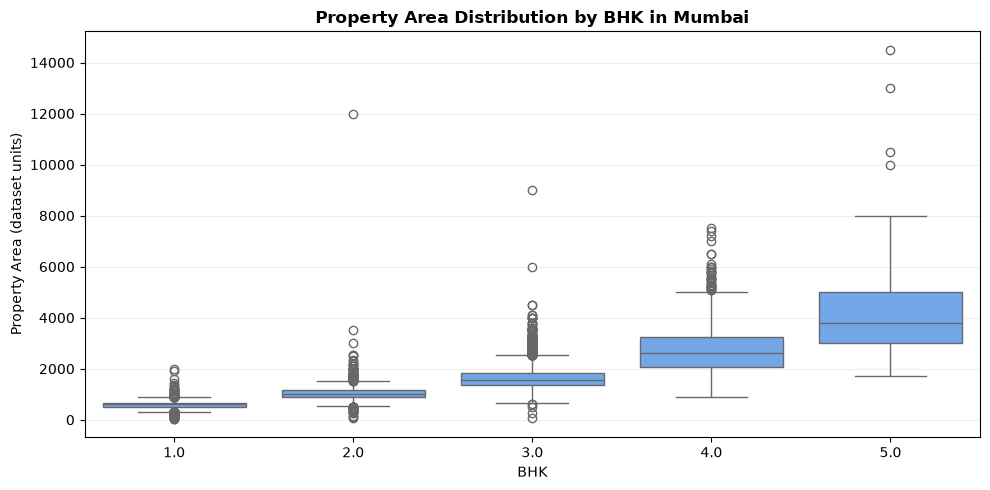

In [24]:
# Property area distribution by BHK

fig, ax = plt.subplots(figsize=(10, 5))

sns.boxplot(
    data=df_review,
    x="BHK_num",
    y="Area_num",
    color="#60a5fa",
    showfliers=True,
    ax=ax
)

ax.set_title(
    "Property Area Distribution by BHK in Mumbai",
    fontweight="bold"
)
ax.set_xlabel("BHK")
ax.set_ylabel("Property Area (dataset units)")
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()


### 4.4 Investigation of Potential Area Unit Inconsistencies

Several listings report unusually small property areas relative to their BHK category.

A possible explanation is inconsistent use of square meters and square feet. To investigate this hypothesis, we compare the reported areas with their hypothetical values after conversion from square meters to square feet.

This analysis is diagnostic only. No automatic unit conversion will be applied without additional evidence.

In [25]:
# Investigate possible mixed area units

unit_review = area_review.loc[
    area_review["Suspicious_Area"]
].copy()

# Hypothetical conversion from square meters to square feet
unit_review["Area_if_sqm_to_sqft"] = (
    unit_review["Area_num"] * 10.7639
)

unit_review["Median_Area_by_BHK"] = (
    unit_review["BHK_num"].map(
        area_review.groupby("BHK_num")["Area_num"].median()
    )
)

unit_review["Original_Ratio"] = (
    unit_review["Area_num"]
    / unit_review["Median_Area_by_BHK"]
)

unit_review["Converted_Ratio"] = (
    unit_review["Area_if_sqm_to_sqft"]
    / unit_review["Median_Area_by_BHK"]
)

display(
    unit_review[
        [
            "Title",
            "BHK_num",
            "Area_num",
            "Area_if_sqm_to_sqft",
            "Median_Area_by_BHK",
            "Original_Ratio",
            "Converted_Ratio"
        ]
    ].sort_values("Area_num").head(25).round(2)
)


,Title,BHK_num,Area_num,Area_if_sqm_to_sqft,Median_Area_by_BHK,Original_Ratio,Converted_Ratio
1108,1BHK Residential House for Rent in,1.0,50.0,538.19,600.0,0.08,0.9
20169,1BHK Multistorey Apartment for Rent in Hiranan...,1.0,50.0,538.19,600.0,0.08,0.9
10197,1BHK Multistorey Apartment for Rent in Godrej ...,1.0,53.0,570.49,600.0,0.09,0.95
15731,1BHK Multistorey Apartment for Rent in Godrej ...,1.0,53.0,570.49,600.0,0.09,0.95
13252,1BHK Multistorey Apartment for Rent in Godrej ...,1.0,53.0,570.49,600.0,0.09,0.95
15994,1BHK Multistorey Apartment for Rent in Godrej ...,1.0,53.0,570.49,600.0,0.09,0.95
2708,2BHK Multistorey Apartment for Rent in Aster a...,2.0,73.0,785.76,1000.0,0.07,0.79
18474,3BHK Multistorey Apartment for Rent in Marina ...,3.0,82.0,882.64,1550.0,0.05,0.57
2429,1BHK Residential House for Rent in Kurla West,1.0,100.0,1076.39,600.0,0.17,1.79
1083,1BHK Multistorey Apartment for Rent in Andheri...,1.0,100.0,1076.39,600.0,0.17,1.79


In [26]:
# Inspect original area values for suspicious listings

original_area_review = df_clean.loc[
    unit_review.index,
    ["Title", "Area"]
].copy()

display(original_area_review.head(30))

print("Examples of original area formats:")
display(
    df_clean["Area"]
    .dropna()
    .astype(str)
    .sample(
        min(20, df_clean["Area"].notna().sum()),
        random_state=42
    )
)


,Title,Area
847,1BHK Multistorey Apartment for Rent in Orlem H...,225.0
994,1BHK Multistorey Apartment for Rent in Ahmad B...,220.0
1007,1BHK Residential House for Rent in Sewri,150.0
1013,1BHK Builder Floor Apartment for Rent in Mazgaon,182.0
1019,1BHK Multistorey Apartment for Rent in,180.0
1034,1BHK Multistorey Apartment for Rent in Prabhadevi,225.0
1058,1BHK Residential House for Rent in Vikhroli,180.0
1079,1BHK Multistorey Apartment for Rent in Mankhurd,225.0
1083,1BHK Multistorey Apartment for Rent in Andheri...,100.0
1108,1BHK Residential House for Rent in,50.0


Examples of original area formats:


3934     1500.0
19138     515.0
1444      500.0
15443    1280.0
9771      750.0
6579     1200.0
2337      800.0
2393      580.0
4437     1079.0
5498     1718.0
16808    1250.0
8931     1500.0
9836      900.0
11498    1500.0
963       400.0
4809     1700.0
16229    1300.0
4391     1700.0
18234    1500.0
16754    1600.0
Name: Area, dtype: str

### 4.5 Area Consistency Filtering

The dataset contains property area values that may be inconsistent with the reported number of bedrooms (BHK).

The original data does not specify the area measurement unit, making it impossible to confirm whether unusually small values represent errors or measurements in a different unit.

For the main analytical dataset, records flagged by the existing area-consistency rule are excluded rather than automatically converted.

This is a conservative analytical filtering decision, not confirmation that the excluded records are incorrect.

In [27]:
# Exclude records flagged by the existing area-consistency rule

records_before = len(df_final)

# Use the previously calculated suspicious-area flags
suspicious_indices = area_review.index[
    area_review["Suspicious_Area"].fillna(False)
]

df_final = df_final.loc[
    ~df_final.index.isin(suspicious_indices)
].copy()

records_after = len(df_final)

print(f"Records before filtering: {records_before:,}")
print(f"Records excluded: {records_before - records_after:,}")
print(f"Records after filtering: {records_after:,}")
print(f"Retention rate: {records_after / records_before * 100:.2f}%")


Records before filtering: 19,285
Records excluded: 93
Records after filtering: 19,192
Retention rate: 99.52%


### 4.6 Balcony Data Quality and Cleaning

The `Balconies` column contains a high proportion of missing values and potentially implausible counts.

Cleaning strategy:
- Convert balcony counts to numeric values.
- Preserve missing values as unknown, not zero.
- Reject negative or non-integer balcony counts.
- Flag properties reporting more than 5 balconies for exclusion from the main analytical sample.
- Retain valid balcony counts from 0 to 5.
- Document the impact of filtering on dataset retention.

The five-balcony threshold is a conservative analytical assumption, not a verified physical limit.

In [28]:
# Work from the current analytical dataset
balcony_data = df_final.copy()

balcony_data["Balconies_num"] = pd.to_numeric(
    balcony_data["Balconies"], errors="coerce"
)

b = balcony_data["Balconies_num"]

missing = b.isna()
negative = b.notna() & (b < 0)
fractional = b.notna() & (b % 1 != 0)
implausible = b.notna() & (b > 5)

# Missing values remain unknown, not zero
invalid = negative | fractional | implausible

balcony_summary = pd.DataFrame({
    "Metric": [
        "Records before filtering",
        "Missing balcony values",
        "Negative balcony counts",
        "Non-integer balcony counts",
        "More than 5 balconies",
        "Records excluded",
        "Records retained"
    ],
    "Count": [
        len(balcony_data),
        int(missing.sum()),
        int(negative.sum()),
        int(fractional.sum()),
        int(implausible.sum()),
        int(invalid.sum()),
        int((~invalid).sum())
    ]
})

display(balcony_summary)

df_final = balcony_data.loc[~invalid].copy()

print(f"Final analytical records: {len(df_final):,}")
print(f"Missing balcony values retained: "
      f"{df_final['Balconies_num'].isna().sum():,}")


,Metric,Count
0,Records before filtering,19192
1,Missing balcony values,10323
2,Negative balcony counts,0
3,Non-integer balcony counts,0
4,More than 5 balconies,0
5,Records excluded,0
6,Records retained,19192


Final analytical records: 19,192
Missing balcony values retained: 10,323


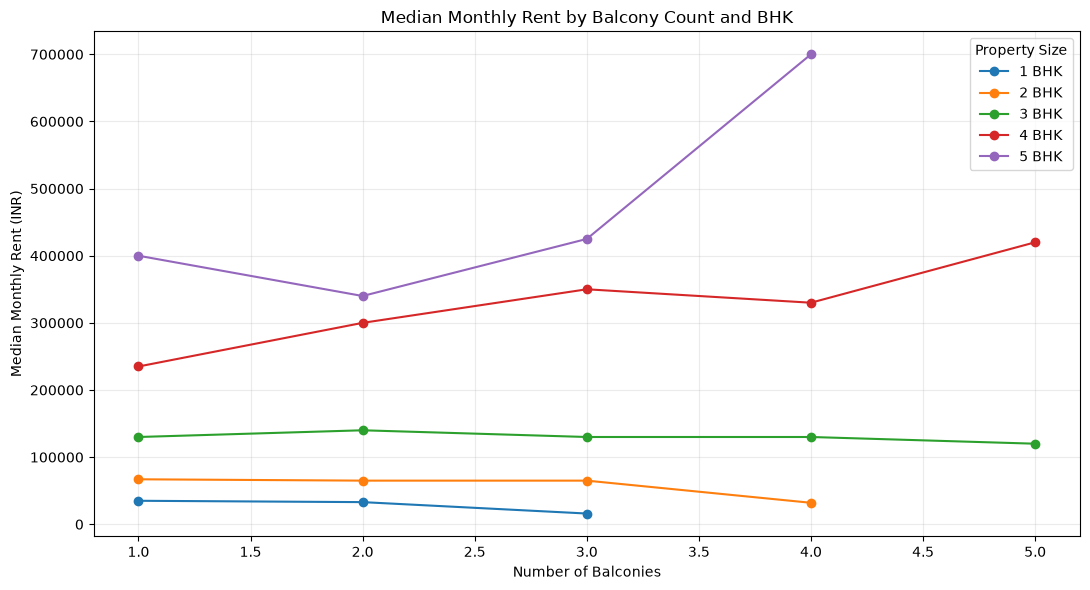

In [29]:
# Exclude unknown balcony counts only for this comparison
balcony_analysis = df_final.dropna(
    subset=["Balconies_num", "BHK_num", "Price_num"]
).copy()

balcony_analysis = balcony_analysis[
    balcony_analysis["BHK_num"].between(1, 5)
]

balcony_stats = (
    balcony_analysis
    .groupby(["BHK_num", "Balconies_num"])["Price_num"]
    .agg(Median_Rent="median", Listings="size")
    .reset_index()
)

# Avoid presenting small groups as representative
balcony_stats = balcony_stats[
    balcony_stats["Listings"] >= 20
]

fig, ax = plt.subplots(figsize=(11, 6))

for bhk, group in balcony_stats.groupby("BHK_num"):
    ax.plot(
        group["Balconies_num"],
        group["Median_Rent"],
        marker="o",
        label=f"{int(bhk)} BHK"
    )

ax.set_title("Median Monthly Rent by Balcony Count and BHK")
ax.set_xlabel("Number of Balconies")
ax.set_ylabel("Median Monthly Rent (INR)")
ax.legend(title="Property Size")
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [30]:
# Sample sizes for each balcony and BHK combination

balcony_counts = (
    df_final.dropna(subset=["Balconies_num", "BHK_num"])
    .groupby(["BHK_num", "Balconies_num"])
    .size()
    .unstack(fill_value=0)
)

display(balcony_counts)


Balconies_num,1.0,2.0,3.0,4.0,5.0
BHK_num,,,,,
1.0,869,295,186,6,0
2.0,1722,985,422,107,7
3.0,1472,765,680,225,39
4.0,324,217,189,156,58
5.0,23,46,44,21,11


In [31]:
# Balcony consistency filtering by property size

balcony_limits = {
    1: 2,
    2: 3,
    3: 4,
    4: 5,
    5: 5
}

records_before = len(df_final)

max_balconies = df_final["BHK_num"].map(balcony_limits)

invalid_balconies = (
    df_final["Balconies_num"].notna()
    & max_balconies.notna()
    & (df_final["Balconies_num"] > max_balconies)
)

# Keep excluded records for audit
balcony_excluded = df_final.loc[invalid_balconies].copy()

display(
    balcony_excluded[
        ["Title", "BHK_num", "Balconies_num", "Price_num"]
    ].head(20)
)

df_final = df_final.loc[~invalid_balconies].copy()

print(f"Records before: {records_before:,}")
print(f"Records excluded: {len(balcony_excluded):,}")
print(f"Records remaining: {len(df_final):,}")


,Title,BHK_num,Balconies_num,Price_num
38,1BHK Multistorey Apartment for Rent in Sea Cro...,1.0,3.0,27000.0
54,1BHK Multistorey Apartment for Rent in JP Nort...,1.0,3.0,19000.0
153,3BHK Multistorey Apartment for Rent in Bombay ...,3.0,5.0,250000.0
192,3BHK Multistorey Apartment for Rent in Kandiva...,3.0,5.0,65000.0
303,1BHK Multistorey Apartment for Rent in Jay Vij...,1.0,3.0,6500.0
310,2BHK Multistorey Apartment for Rent in JK IRIS...,2.0,4.0,32000.0
361,2BHK Multistorey Apartment for Rent in Kohinoo...,2.0,4.0,60000.0
366,2BHK Multistorey Apartment for Rent in The Add...,2.0,4.0,25500.0
375,2BHK Multistorey Apartment for Rent in Codenam...,2.0,4.0,28000.0
377,2BHK Multistorey Apartment for Rent in JK IRIS...,2.0,4.0,28000.0


Records before: 19,192
Records excluded: 345
Records remaining: 18,847


### Balcony Consistency Filtering

Balcony counts were evaluated relative to the reported number of bedrooms (BHK).

Extremely high balcony counts and unusual bedroom-to-balcony combinations were identified as potential data quality issues.

To create a more consistent analytical sample, conservative BHK-specific balcony thresholds were applied.

Records exceeding these thresholds were excluded from the main analysis and retained separately for auditing.

Missing balcony values were preserved because missing information does not imply the absence of balconies.

**Limitation:** These thresholds are analytical assumptions rather than verified building regulations. Some legitimate properties may therefore be excluded.

In [32]:
# Bathroom distribution by property size

bathroom_matrix = pd.crosstab(
    df_final["BHK_num"],
    df_final["Bathrooms_num"]
)

display(bathroom_matrix)


Bathrooms_num,1.0,2.0,3.0,4.0,5.0,6.0
BHK_num,,,,,,
1.0,2203,1959,5,1,0,0
2.0,200,7380,264,3,0,0
3.0,18,685,3913,598,30,0
4.0,4,8,164,854,299,56
5.0,0,0,4,35,111,38


In [33]:
# Bathroom consistency filtering

records_before = len(df_final)

bathroom_invalid = (
    df_final["Bathrooms_num"].notna()
    & df_final["BHK_num"].notna()
    & (df_final["Bathrooms_num"] > df_final["BHK_num"] + 2)
)

bathroom_excluded = df_final.loc[bathroom_invalid].copy()

df_final = df_final.loc[~bathroom_invalid].copy()

print(f"Records before: {records_before:,}")
print(f"Records excluded: {len(bathroom_excluded):,}")
print(f"Records remaining: {len(df_final):,}")


Records before: 18,847
Records excluded: 1
Records remaining: 18,846


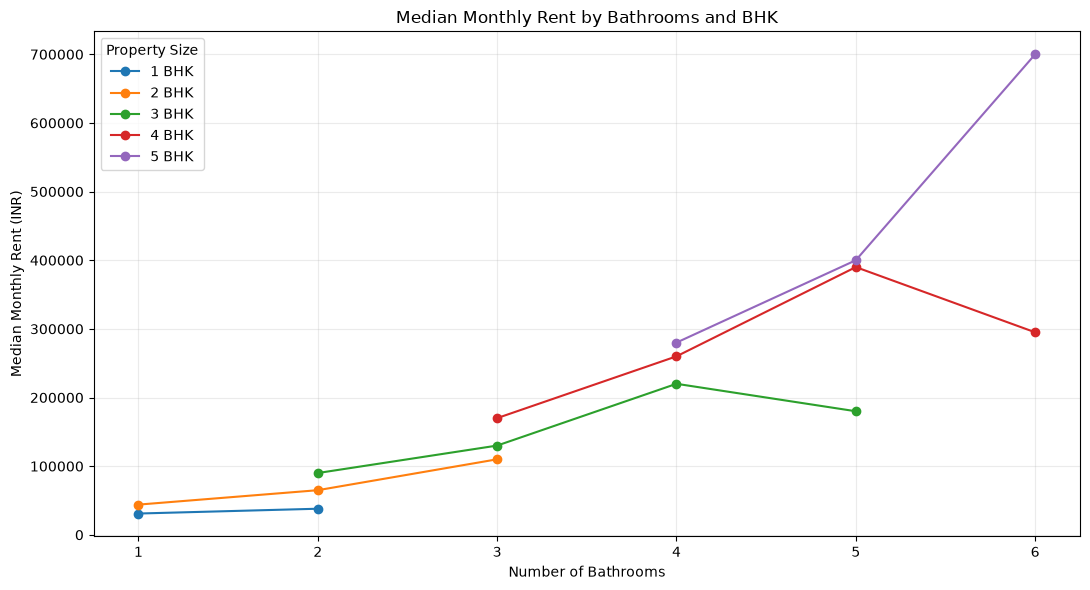

In [34]:
bathroom_rent = (
    df_final.dropna(
        subset=["BHK_num", "Bathrooms_num", "Price_num"]
    )
    .groupby(["BHK_num", "Bathrooms_num"])["Price_num"]
    .agg(Median_Rent="median", Listings="size")
    .reset_index()
)

# Exclude groups with insufficient observations
bathroom_rent = bathroom_rent[
    bathroom_rent["Listings"] >= 30
]

fig, ax = plt.subplots(figsize=(11, 6))

for bhk, group in bathroom_rent.groupby("BHK_num"):
    ax.plot(
        group["Bathrooms_num"],
        group["Median_Rent"],
        marker="o",
        label=f"{int(bhk)} BHK"
    )

ax.set_title("Median Monthly Rent by Bathrooms and BHK")
ax.set_xlabel("Number of Bathrooms")
ax.set_ylabel("Median Monthly Rent (INR)")
ax.legend(title="Property Size")
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


In [36]:
# Inspect 5 BHK properties with 6 bathrooms

luxury_review = df_final.loc[
    (df_final["BHK_num"] == 5)
    & (df_final["Bathrooms_num"] == 6)
].copy()

# Recalculate rent per area if necessary
luxury_review["Rent_per_Area"] = (
    luxury_review["Price_num"] /
    luxury_review["Area_num"].replace(0, float("nan"))
)

# Display available property information
columns = [
    "Title",
    "Area_num",
    "Price_num",
    "Rent_per_Area"
]

display(
    luxury_review[columns]
    .sort_values("Price_num", ascending=False)
    .head(15)
)

print("Properties:", len(luxury_review))
print("Median rent:", luxury_review["Price_num"].median())
print("Median area:", luxury_review["Area_num"].median())
print(
    "Median rent per area:",
    luxury_review["Rent_per_Area"].median()
)


,Title,Area_num,Price_num,Rent_per_Area
10718,5BHK Multistorey Apartment for Rent in Prabhadevi,14500.0,3000000.0,206.896552
16704,5BHK Multistorey Apartment for Rent in Navroze...,6000.0,1500000.0,250.0
9249,5BHK Multistorey Apartment for Rent in Beaumon...,5500.0,1400000.0,254.545455
14639,5BHK Villa for Rent in Indiabulls Blu at Worli,7000.0,1350000.0,192.857143
9286,5BHK Multistorey Apartment for Rent in Bayview...,5500.0,1100000.0,200.0
7963,5BHK Multistorey Apartment for Rent in Beaumon...,4200.0,1000000.0,238.095238
20109,5BHK Multistorey Apartment for Rent in Lower P...,5833.0,950000.0,162.86645
3938,5BHK Multistorey Apartment for Rent in Kanchan...,5900.0,950000.0,161.016949
3573,5BHK Multistorey Apartment for Rent in Khar West,4300.0,900000.0,209.302326
6444,5BHK Multistorey Apartment for Rent in Khar West,5000.0,870000.0,174.0


Properties: 38
Median rent: 700000.0
Median area: 5000.0
Median rent per area: 138.0


### Bathroom Consistency — Final Assessment

Bathroom counts were assessed in relation to the number of bedrooms (BHK) and monthly rental prices.

The analysis identified a general association between larger bedroom-bathroom configurations and higher median rents.

A detailed review of 38 properties with five bedrooms and six bathrooms found a median monthly rent of INR 700,000 and a median reported area of 5,000 units.

These properties were retained because their bathroom configurations and rental values are plausible for high-end residential listings, although individual listing accuracy has not been independently verified.

A conservative consistency filter was applied to extreme bedroom-bathroom combinations.

**Conclusion:** Bathroom count remains a useful explanatory variable for rental price analysis. Differences in location, area, and property quality must be considered when interpreting the results.

## 5. Furnishing Status and Rental Market Analysis

This section investigates how furnishing status relates to monthly rental prices in Mumbai.

We examine four questions:

1. How are rental properties distributed across furnishing categories?
2. How does median monthly rent vary by furnishing status?
3. Does the relationship persist when comparing properties with the same BHK?
4. How does rental price per unit of area differ across furnishing categories?

All comparisons use the cleaned analytical dataset. Missing or unrecognized furnishing categories are excluded only from furnishing-specific analyses.

In [37]:
# Prepare furnishing analysis
df_furnished = df_final.copy()

print("Original furnishing categories:")
display(df_furnished["Furnished"].value_counts(dropna=False))

# Standardize category labels
furnished_map = {
    "furnished": "Furnished",
    "fully furnished": "Furnished",
    "semi-furnished": "Semi-Furnished",
    "semi furnished": "Semi-Furnished",
    "unfurnished": "Unfurnished",
    "not furnished": "Unfurnished"
}

df_furnished["Furnished_clean"] = (
    df_furnished["Furnished"]
    .astype("string")
    .str.strip()
    .str.lower()
    .map(furnished_map)
)

order = ["Unfurnished", "Semi-Furnished", "Furnished"]

print("\nStandardized furnishing categories:")
display(df_furnished["Furnished_clean"].value_counts(dropna=False))

print("\nUnrecognized or missing furnishing values:",
      df_furnished["Furnished_clean"].isna().sum())

# Keep valid categories for furnishing analysis only
df_furnished = df_furnished[
    df_furnished["Furnished_clean"].isin(order)
].copy()


Original furnishing categories:


Furnished
Semi-Furnished    8256
Unfurnished       5649
Furnished         4928
NaN                 13
Name: count, dtype: int64


Standardized furnishing categories:


Furnished_clean
Semi-Furnished    8256
Unfurnished       5649
Furnished         4928
NaN                 13
Name: count, dtype: int64


Unrecognized or missing furnishing values: 13


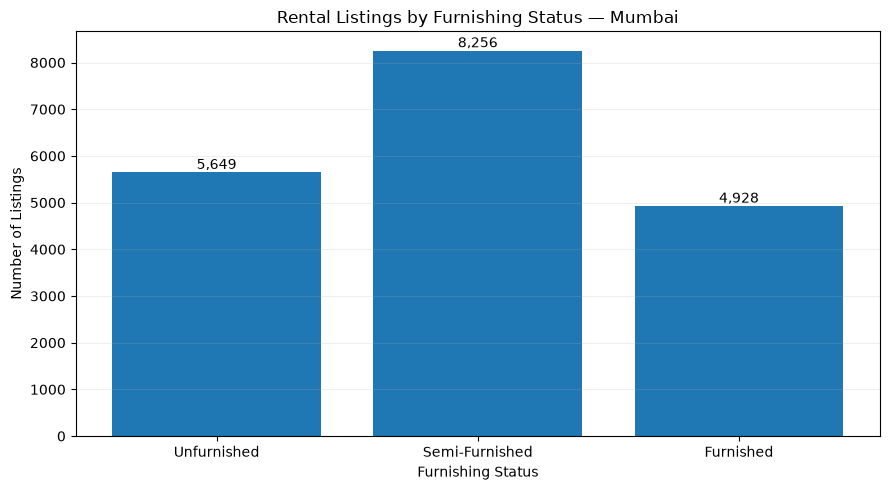

In [38]:
counts = df_furnished["Furnished_clean"].value_counts().reindex(order, fill_value=0)

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(counts.index, counts.values)

for bar, value in zip(bars, counts.values):
    ax.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f"{value:,}",
        ha="center",
        va="bottom"
    )

ax.set_title("Rental Listings by Furnishing Status — Mumbai")
ax.set_xlabel("Furnishing Status")
ax.set_ylabel("Number of Listings")
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()


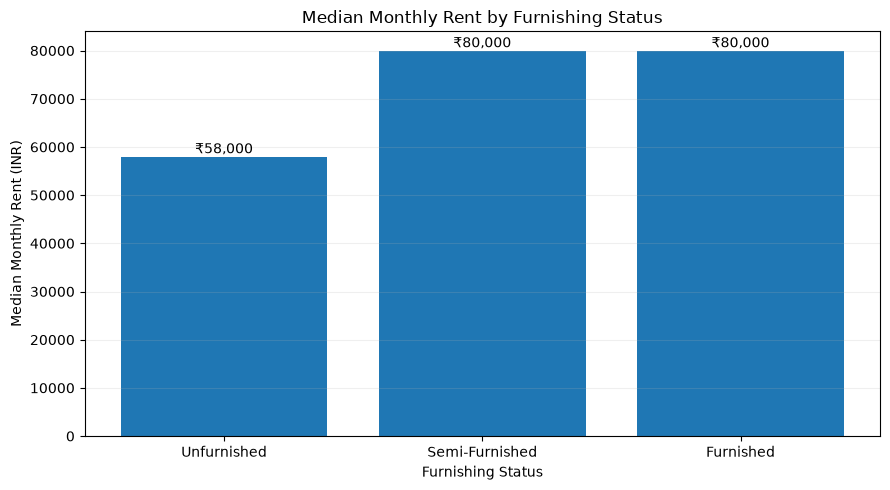

In [39]:
rent_by_furnishing = (
    df_furnished.groupby("Furnished_clean")["Price_num"]
    .median()
    .reindex(order)
)

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(rent_by_furnishing.index, rent_by_furnishing.values)

for bar, value in zip(bars, rent_by_furnishing.values):
    if pd.notna(value):
        ax.text(
            bar.get_x() + bar.get_width()/2,
            bar.get_height(),
            f"₹{value:,.0f}",
            ha="center",
            va="bottom"
        )

ax.set_title("Median Monthly Rent by Furnishing Status")
ax.set_xlabel("Furnishing Status")
ax.set_ylabel("Median Monthly Rent (INR)")
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()


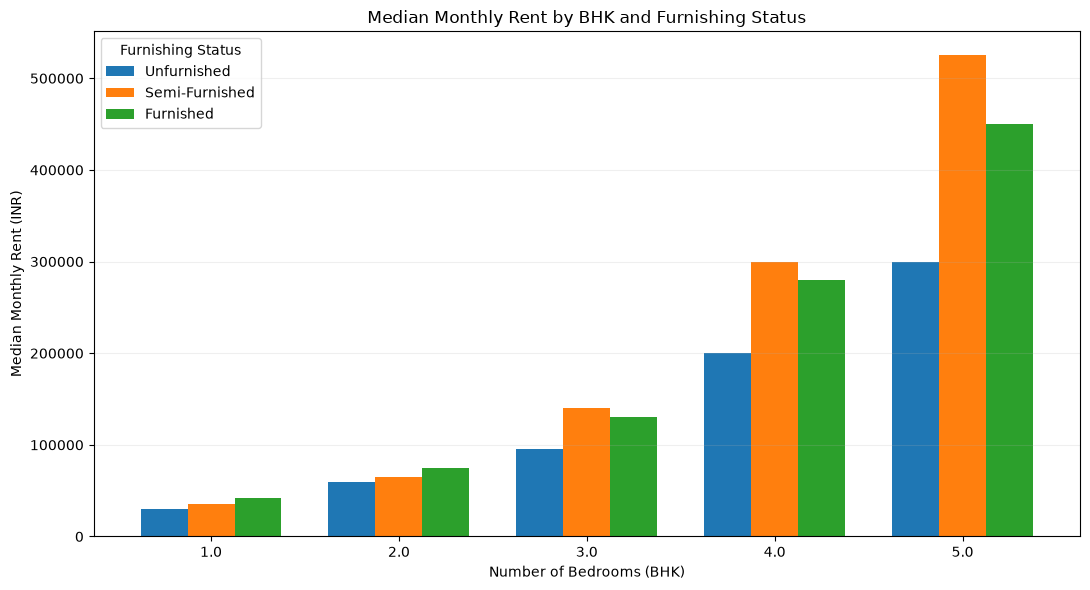

,BHK_num,Furnished_clean,Median_Rent,Listings
0,1.0,Furnished,42000.0,1123
1,1.0,Semi-Furnished,35000.0,1484
2,1.0,Unfurnished,30000.0,1562
3,2.0,Furnished,75000.0,2036
4,2.0,Semi-Furnished,65000.0,3305
5,2.0,Unfurnished,60000.0,2506
6,3.0,Furnished,130000.0,1314
7,3.0,Semi-Furnished,140000.0,2614
8,3.0,Unfurnished,95000.0,1316
9,4.0,Furnished,280000.0,401


In [40]:
furnishing_bhk = (
    df_furnished[
        df_furnished["BHK_num"].between(1, 5)
    ]
    .groupby(["BHK_num", "Furnished_clean"])["Price_num"]
    .agg(Median_Rent="median", Listings="size")
    .reset_index()
)

# Require at least 30 listings per comparison group
furnishing_bhk = furnishing_bhk[
    furnishing_bhk["Listings"] >= 30
]

pivot_rent = furnishing_bhk.pivot(
    index="BHK_num",
    columns="Furnished_clean",
    values="Median_Rent"
).reindex(columns=order)

ax = pivot_rent.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.75
)

ax.set_title("Median Monthly Rent by BHK and Furnishing Status")
ax.set_xlabel("Number of Bedrooms (BHK)")
ax.set_ylabel("Median Monthly Rent (INR)")
ax.legend(title="Furnishing Status")
ax.grid(axis="y", alpha=0.2)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

display(furnishing_bhk)


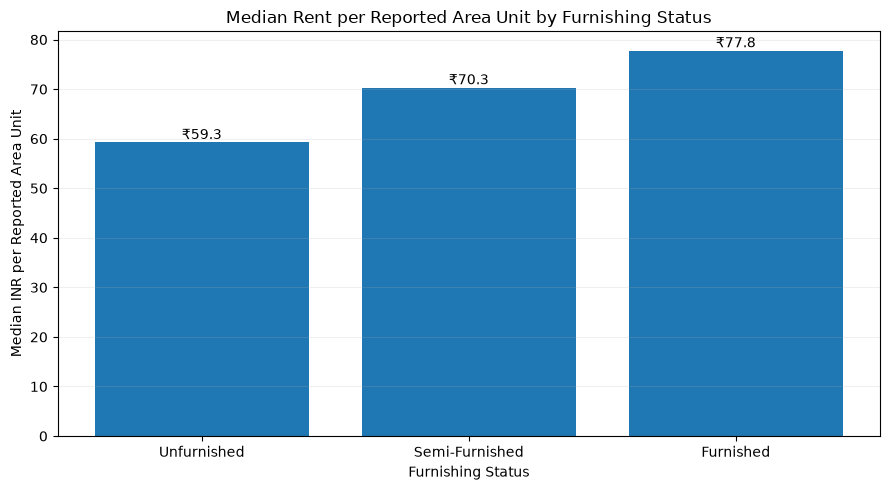

In [41]:
area_analysis = df_furnished[
    (df_furnished["Area_num"] > 0)
    & (df_furnished["Price_num"] > 0)
].copy()

area_analysis["Rent_per_Area"] = (
    area_analysis["Price_num"] /
    area_analysis["Area_num"]
)

# Use median rent per reported area unit
area_summary = (
    area_analysis.groupby("Furnished_clean")["Rent_per_Area"]
    .median()
    .reindex(order)
)

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(area_summary.index, area_summary.values)

for bar, value in zip(bars, area_summary.values):
    if pd.notna(value):
        ax.text(
            bar.get_x() + bar.get_width()/2,
            bar.get_height(),
            f"₹{value:,.1f}",
            ha="center",
            va="bottom"
        )

ax.set_title("Median Rent per Reported Area Unit by Furnishing Status")
ax.set_xlabel("Furnishing Status")
ax.set_ylabel("Median INR per Reported Area Unit")
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()


In [45]:
# Furnishing analysis by BHK

required = ["Furnished_clean", "BHK_num", "Price_num", "Area_num"]

missing = [col for col in required if col not in df_final.columns]

if missing:
    print("Missing columns:", missing)
else:
    furnishing_data = df_final.dropna(subset=required).copy()

    furnishing_data = furnishing_data[
        (furnishing_data["Area_num"] > 0) &
        (furnishing_data["Price_num"] > 0)
    ]

    furnishing_data["Rent_per_Area"] = (
        furnishing_data["Price_num"] / furnishing_data["Area_num"]
    )

    furnishing_review = (
        furnishing_data
        .groupby(["BHK_num", "Furnished_clean"])
        .agg(
            Listings=("Price_num", "size"),
            Median_Rent=("Price_num", "median"),
            Median_Area=("Area_num", "median"),
            Median_Rent_per_Area=("Rent_per_Area", "median")
        )
        .round(2)
    )

    display(furnishing_review)

Listings  Median_Rent  Median_Area  \
BHK_num Furnished_clean                                       
1.0     Furnished            1123      42000.0        625.0   
        Semi-Furnished       1484      35000.0        600.0   
        Unfurnished          1562      30000.0        590.0   
2.0     Furnished            2036      75000.0       1000.0   
        Semi-Furnished       3305      65000.0       1050.0   
        Unfurnished          2506      60000.0       1000.0   
3.0     Furnished            1314     130000.0       1550.0   
        Semi-Furnished       2614     140000.0       1600.0   
        Unfurnished          1316      95000.0       1500.0   
4.0     Furnished             401     280000.0       2650.0   
        Semi-Furnished        753     300000.0       2700.0   
        Unfurnished           231     200000.0       2400.0   
5.0     Furnished              54     450000.0       3500.0   
        Semi-Furnished        100     525000.0       4000.0   
        Unfurnished            34     300000.0       3425.0   

                         Median_Rent_per_Area  
BHK_num Furnished_clean                        
1.0     Furnished                       69.23  
        Semi-Furnished                  56.62  
        Unfurnished                     53.85  
2.0     Furnished                       71.79  
        Semi-Furnished                   62.5  
        Unfurnished                     57.14  
3.0     Furnished                       86.58  
        Semi-Furnished                  83.33  
        Unfurnished                     67.74  
4.0     Furnished                       107.5  
        Semi-Furnished                 116.67  
        Unfurnished                     82.35  
5.0     Furnished                      112.37  
        Semi-Furnished                 114.29  
        Unfurnished                    103.72

In [44]:
# Standardize furnishing categories in the final dataset

df_final["Furnished_clean"] = (
    df_final["Furnished"]
    .astype("string")
    .str.strip()
    .str.title()
    .replace({
        "Semi-Furnished": "Semi-Furnished",
        "Unfurnished": "Unfurnished",
        "Furnished": "Furnished"
    })
)

print(df_final["Furnished_clean"].value_counts(dropna=False))

Furnished_clean
Semi-Furnished    8256
Unfurnished       5649
Furnished         4928
<NA>                13
Name: count, dtype: Int64


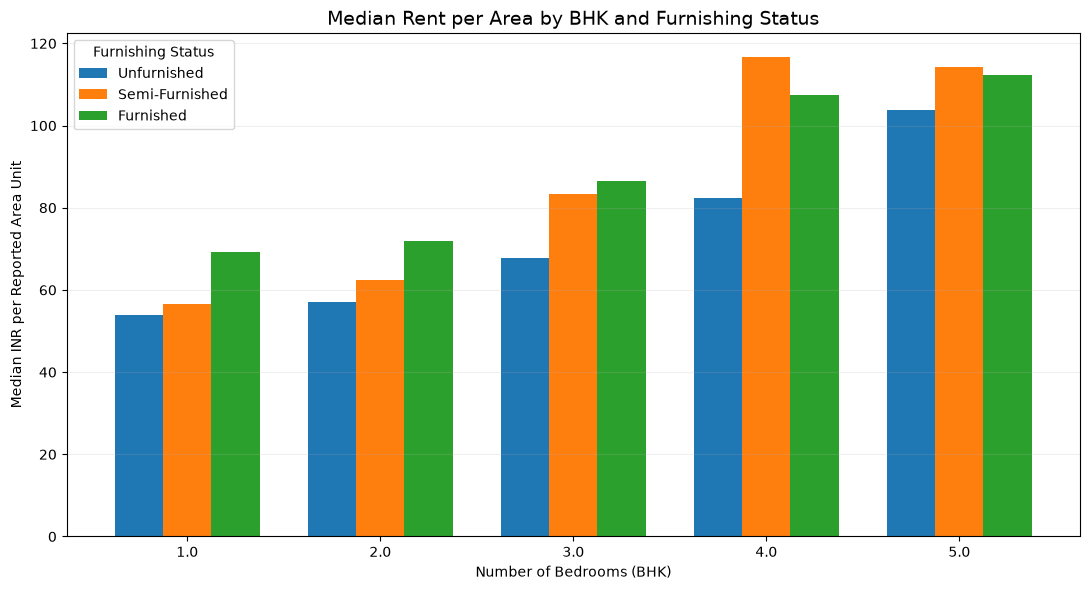

In [46]:
# Median rent per area by BHK and furnishing status

import matplotlib.pyplot as plt

rent_area_comparison = (
    furnishing_review["Median_Rent_per_Area"]
    .unstack("Furnished_clean")
    .reindex(columns=[
        "Unfurnished",
        "Semi-Furnished",
        "Furnished"
    ])
)

ax = rent_area_comparison.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.75
)

ax.set_title(
    "Median Rent per Area by BHK and Furnishing Status",
    fontsize=14
)
ax.set_xlabel("Number of Bedrooms (BHK)")
ax.set_ylabel("Median INR per Reported Area Unit")
ax.legend(title="Furnishing Status")

plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()


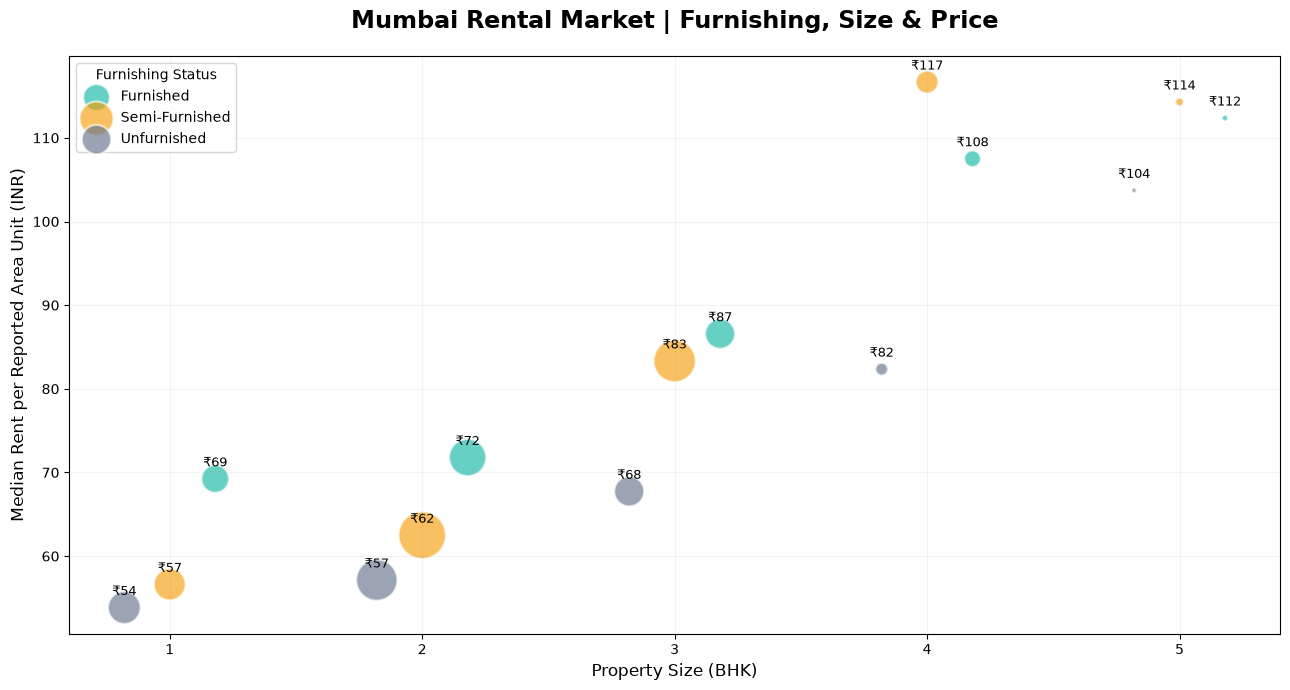

In [47]:
bubble_data = furnishing_review.reset_index()

colors = {
    "Unfurnished": "#64748b",
    "Semi-Furnished": "#f59e0b",
    "Furnished": "#14b8a6"
}

offsets = {
    "Unfurnished": -0.18,
    "Semi-Furnished": 0,
    "Furnished": 0.18
}

fig, ax = plt.subplots(figsize=(13, 7))

for status, group in bubble_data.groupby("Furnished_clean"):
    x = group["BHK_num"] + offsets[status]

    ax.scatter(
        x,
        group["Median_Rent_per_Area"],
        s=group["Listings"] * 0.35,
        color=colors[status],
        alpha=0.65,
        edgecolors="white",
        linewidth=1.5,
        label=status
    )

    for xpos, (_, row) in zip(x, group.iterrows()):
        ax.annotate(
            f"₹{row['Median_Rent_per_Area']:.0f}",
            (xpos, row["Median_Rent_per_Area"]),
            xytext=(0, 9),
            textcoords="offset points",
            ha="center",
            fontsize=9
        )

ax.set_title(
    "Mumbai Rental Market | Furnishing, Size & Price",
    fontsize=17,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Property Size (BHK)", fontsize=12)
ax.set_ylabel("Median Rent per Reported Area Unit (INR)", fontsize=12)

ax.set_xticks([1, 2, 3, 4, 5])
ax.grid(alpha=0.15)
ax.legend(title="Furnishing Status", loc="upper left")

plt.tight_layout()
plt.show()


### Furnishing Status — Interpretation

The relationship between furnishing status and rental prices varies across property sizes.

For 1–2 BHK properties, furnished apartments consistently show higher median monthly rents than semi-furnished and unfurnished properties.

For 3–5 BHK properties, semi-furnished listings sometimes have higher median monthly rents. However, these properties also tend to have larger median floor areas.

In the 5 BHK segment, the median rent per reported area unit is similar for furnished and semi-furnished properties, suggesting that property size partly explains the difference in total rent.

These findings do not provide sufficient evidence to classify the higher-priced semi-furnished listings as erroneous.

Further analysis of property location and sample size would help explain the remaining differences.

In [49]:
# Inspect property facing categories

print("Facing categories:")
display(df_final["Facing"].value_counts(dropna=False))

print("\nMissing facing values:")
print(df_final["Facing"].isna().sum())


Facing categories:


Facing
East            9397
North - East    2674
Unknown         2068
West            1850
North           1316
South -West      688
North - West     381
South - East     255
South            217
Name: count, dtype: int64


Missing facing values:
0


In [50]:
# Facing: standardize property orientations

import pandas as pd

df_final["Facing_clean"] = (
    df_final["Facing"]
    .astype("string")
    .str.strip()
    .str.title()
    .replace({
        "": pd.NA,
        "Nan": pd.NA,
        "None": pd.NA,
        "North-East": "North East",
        "North-West": "North West",
        "South-East": "South East",
        "South-West": "South West"
    })
)

print("Facing categories:")
display(df_final["Facing_clean"].value_counts(dropna=False))


Facing categories:


Facing_clean
East            9397
North - East    2674
Unknown         2068
West            1850
North           1316
South -West      688
North - West     381
South - East     255
South            217
Name: count, dtype: Int64

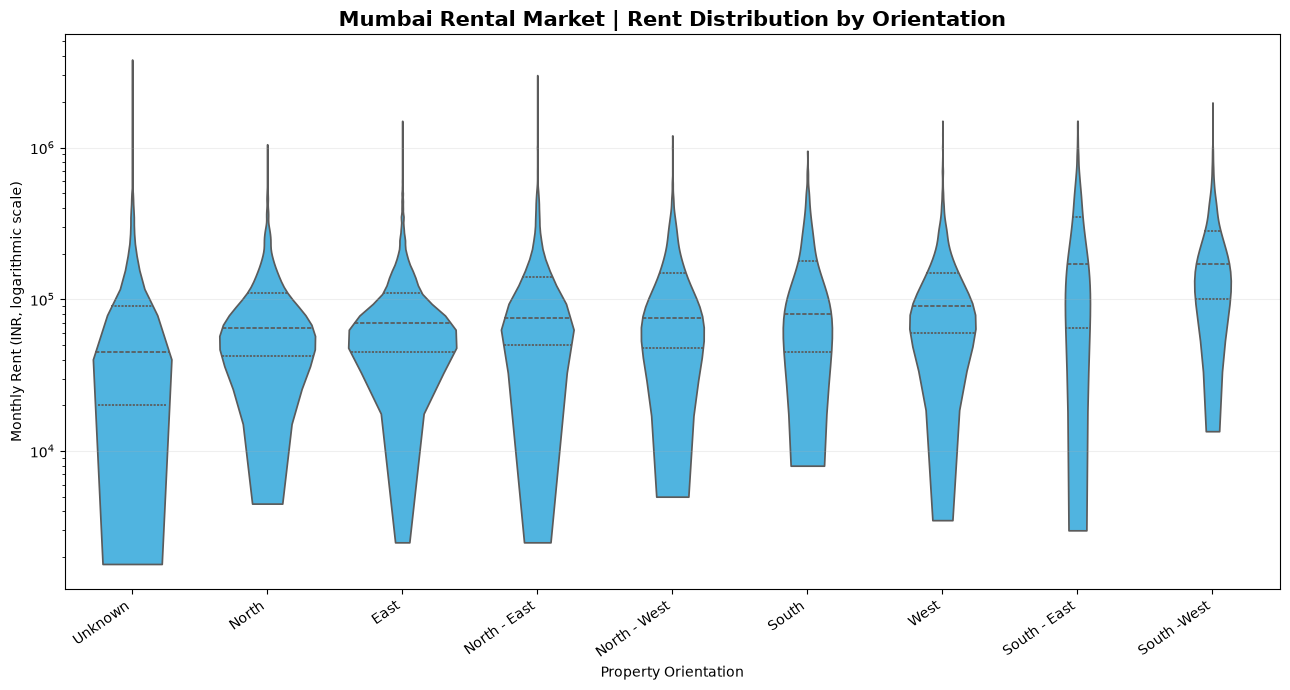

In [51]:
# Rental price distribution by property orientation

facing_data = df_final.dropna(
    subset=["Facing_clean", "Price_num"]
).copy()

facing_data = facing_data[
    facing_data["Price_num"] > 0
]

# Keep orientations with sufficient observations
counts = facing_data["Facing_clean"].value_counts()
valid_facing = counts[counts >= 30].index

facing_data = facing_data[
    facing_data["Facing_clean"].isin(valid_facing)
]

order = (
    facing_data.groupby("Facing_clean")["Price_num"]
    .median()
    .sort_values()
    .index
)

plt.figure(figsize=(13, 7))

sns.violinplot(
    data=facing_data,
    x="Facing_clean",
    y="Price_num",
    order=order,
    inner="quartile",
    cut=0,
    color="#38bdf8"
)

plt.yscale("log")
plt.title(
    "Mumbai Rental Market | Rent Distribution by Orientation",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("Property Orientation")
plt.ylabel("Monthly Rent (INR, logarithmic scale)")
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()


In [52]:
# Orientation summary

facing_summary = (
    facing_data.groupby("Facing_clean")
    .agg(
        Listings=("Price_num", "size"),
        Median_Rent=("Price_num", "median"),
        Median_Area=("Area_num", "median")
    )
    .sort_values("Median_Rent", ascending=False)
)

display(facing_summary)


,Listings,Median_Rent,Median_Area
Facing_clean,,,
South -West,688,170000.0,1500.0
South - East,255,170000.0,1450.0
West,1850,90000.0,1200.0
South,217,80000.0,1180.0
North - East,2674,75000.0,1200.0
North - West,381,75000.0,1151.0
East,9397,69999.0,1052.0
North,1316,65000.0,1100.0
Unknown,2068,45000.0,837.5


### Property Orientation and Rental Prices

This section investigates whether property orientation is associated with rental price differences in Mumbai.

Orientation labels are standardized, and categories with fewer than 30 observations are excluded from this specific visualization to avoid unreliable comparisons.

A violin plot is used to visualize rental price distributions, including their median and quartiles.

Differences between orientations should be interpreted cautiously because property size, location, and building characteristics may also influence rental prices.

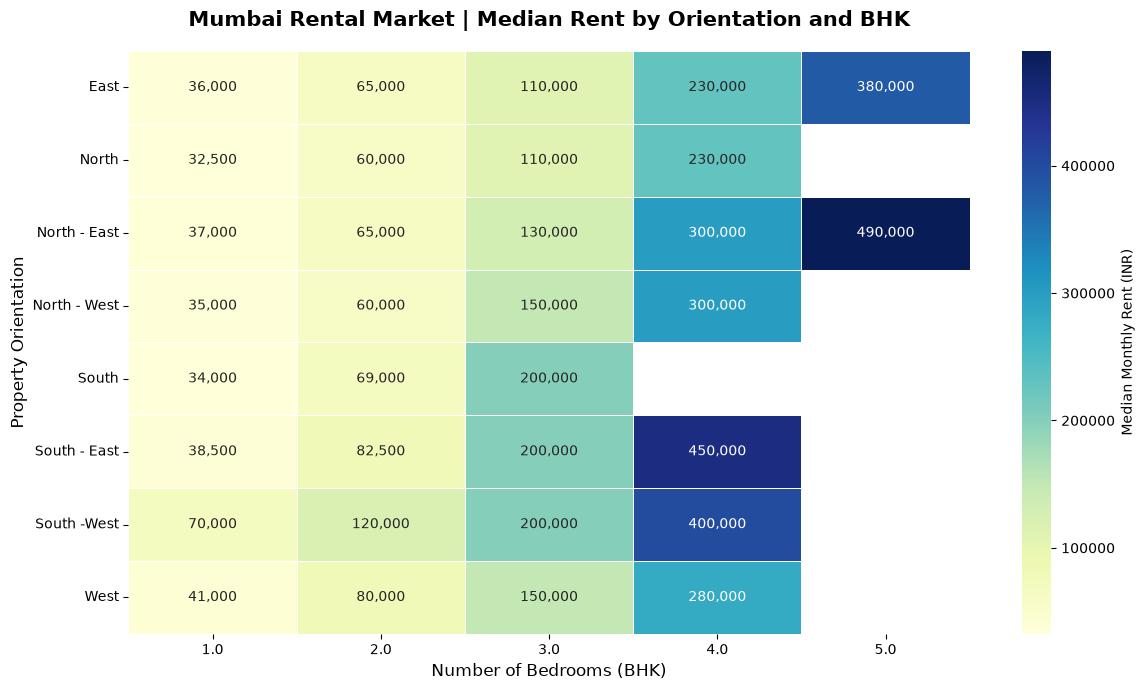

,Facing_clean,BHK_num,Median_Rent,Listings
30,South -West,1.0,70000.0,92
35,West,1.0,41000.0,334
25,South - East,1.0,38500.0,41
10,North - East,1.0,37000.0,447
0,East,1.0,36000.0,2034
15,North - West,1.0,35000.0,64
20,South,1.0,34000.0,49
5,North,1.0,32500.0,297
31,South -West,2.0,120000.0,228
26,South - East,2.0,82500.0,70


In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Select valid records
orientation_data = df_final.loc[
    df_final["Facing_clean"].notna()
    & (df_final["Facing_clean"] != "Unknown")
    & df_final["BHK_num"].between(1, 5)
    & (df_final["Price_num"] > 0)
].copy()

# 2. Calculate median rent and sample size
orientation_summary = (
    orientation_data
    .groupby(
        ["Facing_clean", "BHK_num"],
        observed=True
    )
    .agg(
        Median_Rent=("Price_num", "median"),
        Listings=("Price_num", "size")
    )
    .reset_index()
)

# 3. Exclude unreliable groups with fewer than 20 listings
orientation_summary.loc[
    orientation_summary["Listings"] < 20,
    "Median_Rent"
] = np.nan

# 4. Create heatmap matrix
heatmap_data = orientation_summary.pivot(
    index="Facing_clean",
    columns="BHK_num",
    values="Median_Rent"
)

# 5. Convert pandas nullable values to NumPy floats
# This prevents the NAType error in Seaborn
heatmap_data = heatmap_data.apply(
    lambda col: pd.Series(
        pd.to_numeric(col, errors="coerce").to_numpy(
            dtype="float64",
            na_value=np.nan
        ),
        index=col.index
    )
)

# 6. Plot heatmap
plt.figure(figsize=(12, 7))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=",.0f",
    cmap="YlGnBu",
    linewidths=0.5,
    mask=heatmap_data.isna(),
    cbar_kws={
        "label": "Median Monthly Rent (INR)"
    }
)

plt.title(
    "Mumbai Rental Market | Median Rent by Orientation and BHK",
    fontsize=15,
    fontweight="bold",
    pad=18
)

plt.xlabel("Number of Bedrooms (BHK)", fontsize=12)
plt.ylabel("Property Orientation", fontsize=12)

plt.tight_layout()
plt.show()

# 7. Display supporting statistics
display(
    orientation_summary.sort_values(
        ["BHK_num", "Median_Rent"],
        ascending=[True, False]
    )
)


In [ ]:
### Orientation, Property Size and Rental Value

The previous heatmap revealed substantial differences in median rents between orientations, even within the same BHK categories.

However, bedroom count alone does not control for property size. We therefore compare median rent per reported area unit to investigate whether these differences persist after normalizing for area.

This is a descriptive comparison, not evidence that orientation directly causes higher rental prices.

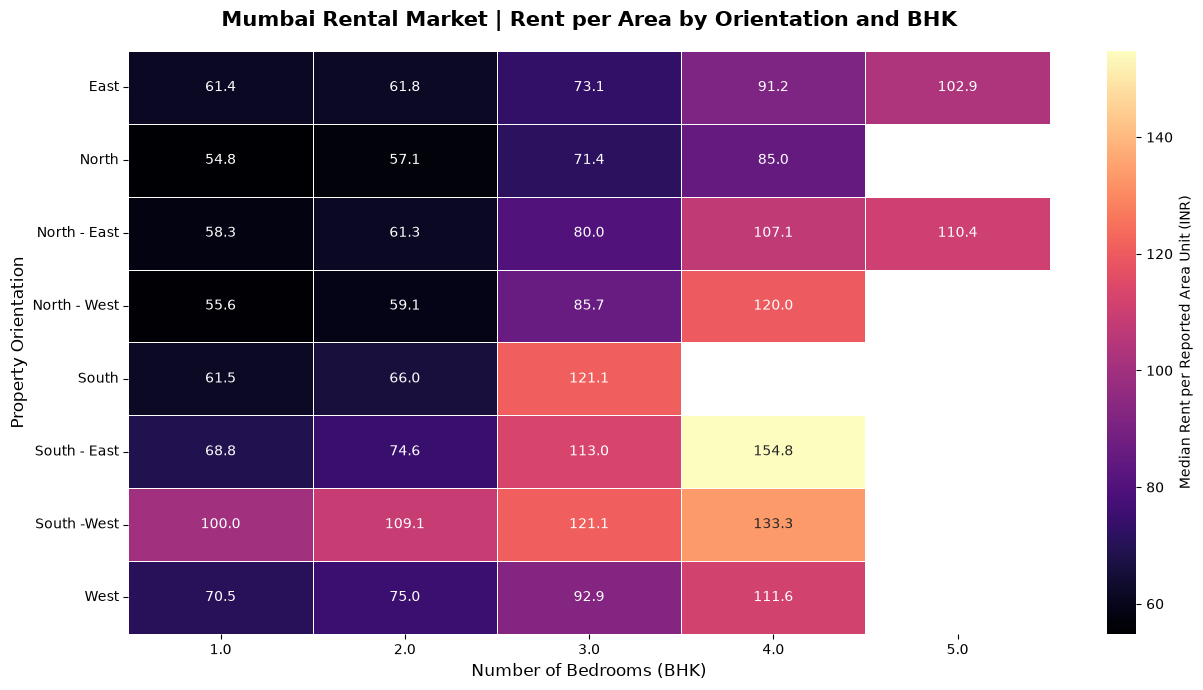

Total records analyzed: 16778
Minimum listings per displayed group: 20


,Facing_clean,BHK_num,Listings,Median_Rent,Median_Area,Median_Rent_per_Area,Reliable_Sample
30,South -West,1.0,92,70000.0,700.0,100.0,True
35,West,1.0,334,41000.0,630.0,70.49,True
25,South - East,1.0,41,38500.0,600.0,68.75,True
20,South,1.0,49,34000.0,550.0,61.54,True
0,East,1.0,2034,36000.0,601.0,61.42,True
10,North - East,1.0,447,37000.0,650.0,58.33,True
15,North - West,1.0,64,35000.0,600.0,55.57,True
5,North,1.0,297,32500.0,600.0,54.83,True
31,South -West,2.0,228,120000.0,1100.0,109.09,True
36,West,2.0,740,80000.0,1050.0,75.0,True


In [60]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Summarize rent per area within each orientation and BHK
area_summary = (
    area_orientation
    .groupby(["Facing_clean", "BHK_num"], observed=True)
    .agg(
        Listings=("Price_num", "size"),
        Median_Rent=("Price_num", "median"),
        Median_Area=("Area_num", "median"),
        Median_Rent_per_Area=("Rent_per_Area", "median")
    )
    .reset_index()
)

# 2. Exclude groups with fewer than 20 listings
# Only their analytical statistics are hidden
# No records are deleted from the dataset
min_listings = 20

area_summary["Reliable_Sample"] = (
    area_summary["Listings"] >= min_listings
)

area_summary["Plot_Value"] = (
    area_summary["Median_Rent_per_Area"]
    .where(area_summary["Reliable_Sample"], np.nan)
)

# 3. Prepare the heatmap matrix
area_heatmap = area_summary.pivot(
    index="Facing_clean",
    columns="BHK_num",
    values="Plot_Value"
)

# Convert nullable pandas values to standard floats
area_heatmap = area_heatmap.apply(
    lambda col: pd.Series(
        pd.to_numeric(col, errors="coerce").to_numpy(
            dtype="float64",
            na_value=np.nan
        ),
        index=col.index
    )
)

# 4. Create heatmap
plt.figure(figsize=(13, 7))

sns.heatmap(
    area_heatmap,
    annot=True,
    fmt=".1f",
    cmap="magma",
    linewidths=0.6,
    linecolor="white",
    mask=area_heatmap.isna(),
    cbar_kws={
        "label": "Median Rent per Reported Area Unit (INR)"
    }
)

plt.title(
    "Mumbai Rental Market | Rent per Area by Orientation and BHK",
    fontsize=15,
    fontweight="bold",
    pad=18
)

plt.xlabel("Number of Bedrooms (BHK)", fontsize=12)
plt.ylabel("Property Orientation", fontsize=12)

plt.tight_layout()
plt.show()

# 5. Display supporting statistics
print("Total records analyzed:", len(area_orientation))
print("Minimum listings per displayed group:", min_listings)

display(
    area_summary[
        [
            "Facing_clean",
            "BHK_num",
            "Listings",
            "Median_Rent",
            "Median_Area",
            "Median_Rent_per_Area",
            "Reliable_Sample"
        ]
    ]
    .sort_values(
        ["BHK_num", "Median_Rent_per_Area"],
        ascending=[True, False]
    )
    .round(2)
)


In [59]:
# Select valid records for orientation analysis
area_orientation = df_final.loc[
    df_final["Facing_clean"].notna()
    & (df_final["Facing_clean"] != "Unknown")
    & df_final["BHK_num"].between(1, 5)
].copy()

# Convert price and area to numeric values
area_orientation["Price_num"] = pd.to_numeric(
    area_orientation["Price_num"], errors="coerce"
)

area_orientation["Area_num"] = pd.to_numeric(
    area_orientation["Area_num"], errors="coerce"
)

# Keep only valid positive prices and areas
area_orientation = area_orientation.loc[
    (area_orientation["Price_num"] > 0)
    & (area_orientation["Area_num"] > 0)
].copy()

# Calculate rent per reported area unit
area_orientation["Rent_per_Area"] = (
    area_orientation["Price_num"]
    / area_orientation["Area_num"]
)

print("Records available for analysis:", len(area_orientation))

Records available for analysis: 16778


In [61]:
# Initial list of Mumbai neighborhoods to investigate
neighborhoods = [
    "Andheri", "Bandra", "Worli", "Juhu",
    "Powai", "Colaba", "Dadar", "Chembur",
    "Kurla", "Malad", "Goregaon", "Kandivali",
    "Borivali", "Santacruz", "Vile Parle",
    "Khar", "Lower Parel", "Prabhadevi",
    "Ghatkopar", "Mulund", "Versova",
    "Sion", "Matunga", "Byculla"
]

# Work on a copy without changing the original dataset
df_geo = df_final.copy()

# Match longer names first to avoid partial matches
neighborhoods = sorted(neighborhoods, key=len, reverse=True)

pattern = r"\b(" + "|".join(
    __import__("re").escape(name) for name in neighborhoods
) + r")\b"

df_geo["Neighborhood"] = (
    df_geo["Title"]
    .astype("string")
    .str.extract(pattern, flags=__import__("re").IGNORECASE, expand=False)
    .str.lower()
    .map({name.lower(): name for name in neighborhoods})
)

# Check geographic coverage
print("Total records:", len(df_geo))
print("Matched records:", df_geo["Neighborhood"].notna().sum())
print("Unmatched records:", df_geo["Neighborhood"].isna().sum())

display(
    df_geo["Neighborhood"]
    .value_counts()
    .rename_axis("Neighborhood")
    .reset_index(name="Listings")
)


Total records: 18846
Matched records: 11657
Unmatched records: 7189


,Neighborhood,Listings
0,Andheri,1504
1,Bandra,1123
2,Chembur,1102
3,Worli,1022
4,Goregaon,1006
5,Kandivali,910
6,Powai,718
7,Malad,527
8,Mulund,458
9,Santacruz,385


### Geographic Rental Market Analysis

Rental prices in Mumbai may vary significantly between neighborhoods due to differences in location, property size, infrastructure, and housing characteristics.

This analysis compares:
- Median monthly rent by neighborhood.
- Median property area by neighborhood.
- Median rent per reported area unit.
- Number of rental listings in each neighborhood.

The objective is to identify spatial patterns in rental values and distinguish high-price locations from areas offering relatively more space for the same budget.

Only neighborhoods with sufficient observations are included in the comparison.

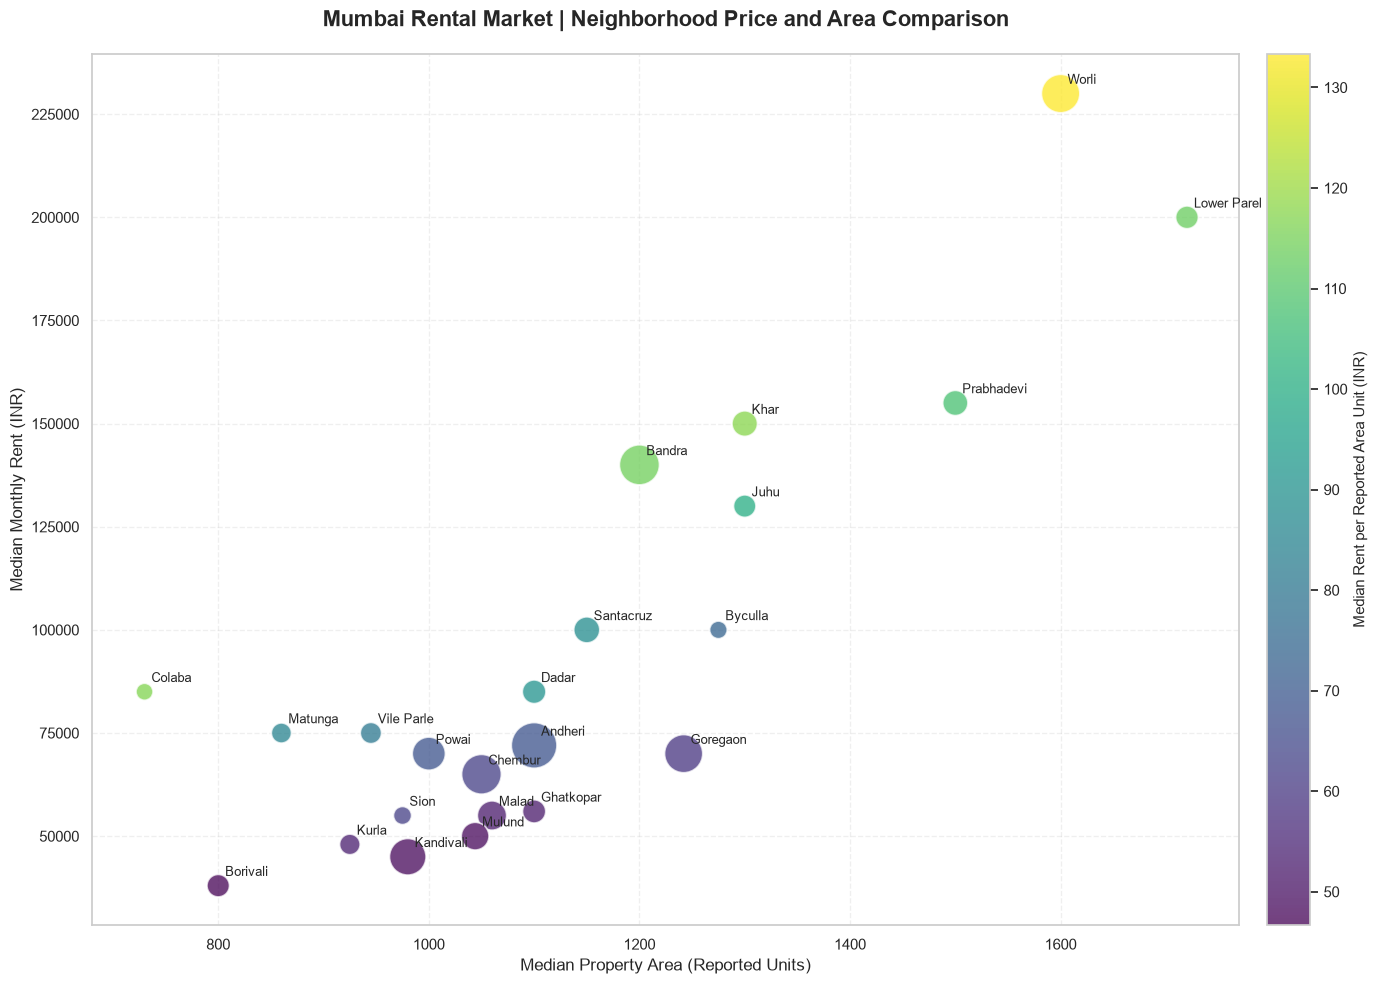

Total properties analyzed: 11657
Neighborhoods displayed: 23
Minimum listings per neighborhood: 50


,Neighborhood,Listings,Median_Rent,Median_Area,Median_Rent_per_Area
23,Worli,1022.0,230000.0,1600.0,133.33
13,Lower Parel,257.0,200000.0,1720.0,113.04
18,Prabhadevi,350.0,155000.0,1500.0,107.90
11,Khar,363.0,150000.0,1300.0,117.65
1,Bandra,1123.0,140000.0,1200.0,114.29
9,Juhu,246.0,130000.0,1300.0,100.00
3,Byculla,92.0,100000.0,1275.0,73.68
19,Santacruz,385.0,100000.0,1150.0,88.00
5,Colaba,76.0,85000.0,730.0,116.52
6,Dadar,289.0,85000.0,1100.0,90.91


In [64]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Prepare geographic analysis dataset
geo_analysis = df_geo.copy()

# Convert relevant columns to numeric
numeric_columns = ["Price_num", "Area_num", "BHK_num"]

for col in numeric_columns:
    geo_analysis[col] = pd.to_numeric(
        geo_analysis[col],
        errors="coerce"
    )

# 2. Select valid records
geo_analysis = geo_analysis.loc[
    geo_analysis["Neighborhood"].notna()
    & (geo_analysis["Price_num"] > 0)
    & (geo_analysis["Area_num"] > 0)
    & geo_analysis["BHK_num"].between(1, 5)
].copy()

# 3. Calculate monthly rent per area unit
geo_analysis["Rent_per_Area"] = (
    geo_analysis["Price_num"]
    / geo_analysis["Area_num"]
)

# 4. Aggregate statistics by neighborhood
neighborhood_summary = (
    geo_analysis
    .groupby("Neighborhood", observed=True)
    .agg(
        Listings=("Price_num", "size"),
        Median_Rent=("Price_num", "median"),
        Median_Area=("Area_num", "median"),
        Median_Rent_per_Area=("Rent_per_Area", "median")
    )
    .reset_index()
)

# 5. Keep neighborhoods with sufficient observations
min_listings = 50

neighborhood_summary = neighborhood_summary.loc[
    neighborhood_summary["Listings"] >= min_listings
].copy()

# Convert summary columns to standard float values
for col in [
    "Listings",
    "Median_Rent",
    "Median_Area",
    "Median_Rent_per_Area"
]:
    neighborhood_summary[col] = (
        pd.to_numeric(
            neighborhood_summary[col],
            errors="coerce"
        )
        .to_numpy(dtype="float64", na_value=np.nan)
    )

# 6. Create bubble chart
sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(15, 10))

bubble_sizes = (
    100
    + neighborhood_summary["Listings"] * 0.65
)

scatter = ax.scatter(
    neighborhood_summary["Median_Area"],
    neighborhood_summary["Median_Rent"],
    s=bubble_sizes,
    c=neighborhood_summary["Median_Rent_per_Area"],
    cmap="viridis",
    alpha=0.75,
    edgecolors="white",
    linewidths=1.2
)

# 7. Add neighborhood labels
for _, row in neighborhood_summary.iterrows():
    ax.annotate(
        row["Neighborhood"],
        (
            row["Median_Area"],
            row["Median_Rent"]
        ),
        xytext=(5, 7),
        textcoords="offset points",
        fontsize=9
    )

# 8. Add colorbar
colorbar = fig.colorbar(
    scatter,
    ax=ax,
    pad=0.02
)

colorbar.set_label(
    "Median Rent per Reported Area Unit (INR)",
    fontsize=11
)

# 9. Format chart
ax.set_title(
    "Mumbai Rental Market | Neighborhood Price and Area Comparison",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_xlabel(
    "Median Property Area (Reported Units)",
    fontsize=12
)

ax.set_ylabel(
    "Median Monthly Rent (INR)",
    fontsize=12
)

ax.ticklabel_format(
    style="plain",
    axis="y"
)

ax.grid(
    True,
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()
plt.show()

# 10. Display summary statistics
print("Total properties analyzed:", len(geo_analysis))
print("Neighborhoods displayed:", len(neighborhood_summary))
print("Minimum listings per neighborhood:", min_listings)

display(
    neighborhood_summary
    .sort_values(
        "Median_Rent",
        ascending=False
    )
    .round(2)
)


### Key Findings: Neighborhood Rental Differences

The neighborhood comparison reveals substantial differences in rental values across Mumbai.

- **Premium rental markets:** Lower Parel, Bandra, Khar, and Prabhadevi show relatively high median rents.
- **More affordable markets:** Borivali, Kandivali, and Kurla have comparatively lower median rents within the analyzed sample.
- **Property size is not the only determinant:** Colaba shows relatively high rents despite smaller median property areas.
- **Market representation varies:** Neighborhoods such as Andheri and Bandra have more listings, while some locations have substantially smaller samples.

These findings suggest that location is strongly associated with rental values. However, differences in bedroom count, building quality, amenities, and property characteristics may also contribute.

**Limitation:** Neighborhoods were identified from listing titles, and the dataset does not necessarily represent the entire Mumbai rental market.

### Neighborhood and Orientation: Rental Price Comparison

This analysis investigates how rental prices vary across Mumbai neighborhoods and property orientations.

To improve comparability, the analysis focuses on 2 BHK properties and compares median monthly rent per reported area unit.

The heatmap aims to identify whether orientation-related price differences persist within individual neighborhoods, rather than simply reflecting differences between expensive and affordable locations.

Groups with fewer than 10 listings are excluded from the visualization to reduce the influence of small samples.

These comparisons are descriptive and do not establish a causal effect of orientation on rental prices.

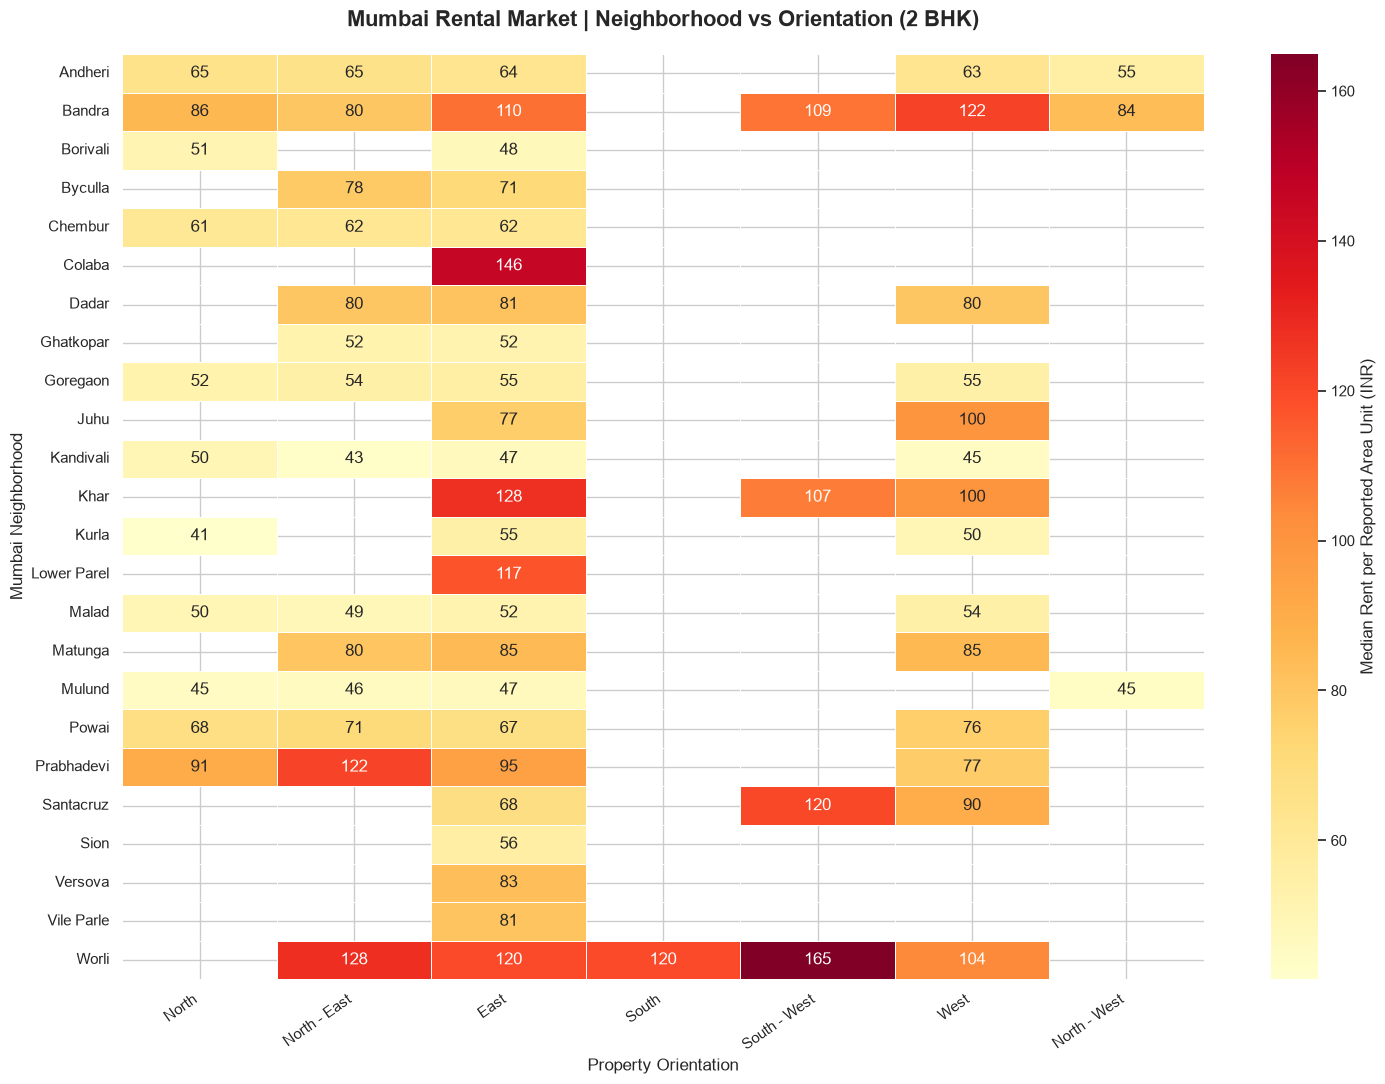

2 BHK properties analyzed: 4250
Minimum listings per displayed group: 10


,Neighborhood,Facing_group,Listings,Median_Rent,Median_Rent_per_Area
6,Andheri,South - West,5,100000.0,86.96
5,Andheri,South - East,1,55000.0,84.62
4,Andheri,South,7,80000.0,83.01
2,Andheri,North - East,74,68500.0,65.3
1,Andheri,North,62,65000.0,65.01
...,...,...,...,...,...
155,Worli,East,116,130000.0,120.0
159,Worli,South,10,150000.0,120.0
160,Worli,South - East,7,150000.0,107.14
158,Worli,North - West,7,150000.0,104.76


In [65]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Start from the geographic analysis dataset
location_orientation = geo_analysis.copy()

# Normalize orientation labels
location_orientation["Facing_group"] = (
    location_orientation["Facing_clean"]
    .astype("string")
    .str.strip()
    .str.title()
    .str.replace(r"\s*-\s*", " - ", regex=True)
)

# 2. Select 2 BHK properties with known orientations
location_orientation = location_orientation.loc[
    location_orientation["Neighborhood"].notna()
    & location_orientation["Facing_group"].notna()
    & (~location_orientation["Facing_group"].isin(["Unknown", "None"]))
    & (location_orientation["BHK_num"] == 2)
    & (location_orientation["Rent_per_Area"] > 0)
].copy()

# 3. Calculate neighborhood-orientation statistics
orientation_location_summary = (
    location_orientation
    .groupby(["Neighborhood", "Facing_group"], observed=True)
    .agg(
        Listings=("Price_num", "size"),
        Median_Rent=("Price_num", "median"),
        Median_Rent_per_Area=("Rent_per_Area", "median")
    )
    .reset_index()
)

# 4. Hide groups with fewer than 10 listings
min_listings = 10

orientation_location_summary["Plot_Value"] = (
    orientation_location_summary["Median_Rent_per_Area"]
    .where(
        orientation_location_summary["Listings"] >= min_listings,
        np.nan
    )
)

# 5. Create heatmap matrix
heatmap_location = orientation_location_summary.pivot(
    index="Neighborhood",
    columns="Facing_group",
    values="Plot_Value"
)

# Set consistent orientation order
orientation_order = [
    "North",
    "North - East",
    "East",
    "South - East",
    "South",
    "South - West",
    "West",
    "North - West"
]

heatmap_location = heatmap_location.reindex(
    columns=orientation_order
)

# Convert nullable values to standard floats
heatmap_location = heatmap_location.apply(
    lambda col: pd.Series(
        pd.to_numeric(col, errors="coerce").to_numpy(
            dtype="float64",
            na_value=np.nan
        ),
        index=col.index
    )
)

# Remove rows and columns without sufficient data
heatmap_location = heatmap_location.dropna(
    axis=0, how="all"
).dropna(
    axis=1, how="all"
)

# 6. Plot heatmap
if heatmap_location.empty:
    print("Not enough observations for the selected threshold.")
else:
    plt.figure(figsize=(15, 11))

    sns.heatmap(
        heatmap_location,
        annot=True,
        fmt=".0f",
        cmap="YlOrRd",
        linewidths=0.5,
        linecolor="white",
        mask=heatmap_location.isna(),
        cbar_kws={
            "label": "Median Rent per Reported Area Unit (INR)"
        }
    )

    plt.title(
        "Mumbai Rental Market | Neighborhood vs Orientation (2 BHK)",
        fontsize=16,
        fontweight="bold",
        pad=20
    )

    plt.xlabel("Property Orientation", fontsize=12)
    plt.ylabel("Mumbai Neighborhood", fontsize=12)

    plt.xticks(rotation=35, ha="right")
    plt.yticks(rotation=0)

    plt.tight_layout()
    plt.show()

# 7. Display supporting statistics
print("2 BHK properties analyzed:", len(location_orientation))
print("Minimum listings per displayed group:", min_listings)

display(
    orientation_location_summary[
        [
            "Neighborhood",
            "Facing_group",
            "Listings",
            "Median_Rent",
            "Median_Rent_per_Area"
        ]
    ]
    .sort_values(
        ["Neighborhood", "Median_Rent_per_Area"],
        ascending=[True, False]
    )
    .round(2)
)


### Key Findings: Neighborhood and Orientation

The analysis of 2 BHK rental properties reveals that orientation-related price differences vary across Mumbai neighborhoods.

In Bandra, west-facing properties show a higher median rent per reported area unit than north-facing properties (approximately INR 122 versus INR 86).

In Worli, southwest-facing properties show a median value of approximately INR 165, compared with INR 104 for west-facing properties.

In contrast, Andheri exhibits relatively small differences across the orientations with sufficient observations.

These findings suggest that the relationship between property orientation and rental value may depend on neighborhood characteristics.

However, the analysis remains descriptive. Differences may also reflect building quality, amenities, property age, and micro-location. Cells with fewer than 10 listings are not displayed, and larger samples would improve the reliability of comparisons.

In [66]:
# Focus on three neighborhoods for detailed comparison
selected_neighborhoods = ["Andheri", "Bandra", "Worli"]

# Use the summary created in the previous analysis
validation_data = orientation_location_summary.loc[
    orientation_location_summary["Neighborhood"].isin(
        selected_neighborhoods
    )
].copy()

# Standardize numeric columns
for col in ["Listings", "Median_Rent", "Median_Rent_per_Area"]:
    validation_data[col] = pd.to_numeric(
        validation_data[col], errors="coerce"
    ).astype(float)

# Define sample size categories
def sample_quality(n):
    if n >= 30:
        return "30+ listings"
    elif n >= 10:
        return "10–29 listings"
    else:
        return "Below 10 listings"

validation_data["Sample_Size_Group"] = (
    validation_data["Listings"].apply(sample_quality)
)

# Keep only groups meeting the heatmap threshold
validated_groups = validation_data.loc[
    validation_data["Listings"] >= 10
].copy()

# Display detailed validation table
display(
    validated_groups[
        [
            "Neighborhood",
            "Facing_group",
            "Listings",
            "Median_Rent",
            "Median_Rent_per_Area",
            "Sample_Size_Group"
        ]
    ]
    .sort_values(
        ["Neighborhood", "Median_Rent_per_Area"],
        ascending=[True, False]
    )
    .round(2)
)

# Summarize data coverage
print("Total validated groups:", len(validated_groups))
print(
    "Groups with 30+ listings:",
    (validated_groups["Listings"] >= 30).sum()
)
print(
    "Groups with 10–29 listings:",
    validated_groups["Listings"].between(10, 29).sum()
)


,Neighborhood,Facing_group,Listings,Median_Rent,Median_Rent_per_Area,Sample_Size_Group
2,Andheri,North - East,74.0,68500.0,65.30,30+ listings
1,Andheri,North,62.0,65000.0,65.01,30+ listings
0,Andheri,East,325.0,65000.0,63.64,30+ listings
7,Andheri,West,30.0,65000.0,63.03,30+ listings
3,Andheri,North - West,11.0,60000.0,55.17,10–29 listings
15,Bandra,West,107.0,120000.0,122.22,30+ listings
8,Bandra,East,155.0,110000.0,110.00,30+ listings
14,Bandra,South - West,86.0,120000.0,109.09,30+ listings
9,Bandra,North,11.0,82000.0,85.71,10–29 listings
11,Bandra,North - West,10.0,97500.0,83.56,10–29 listings


Total validated groups: 16
Groups with 30+ listings: 10
Groups with 10–29 listings: 6


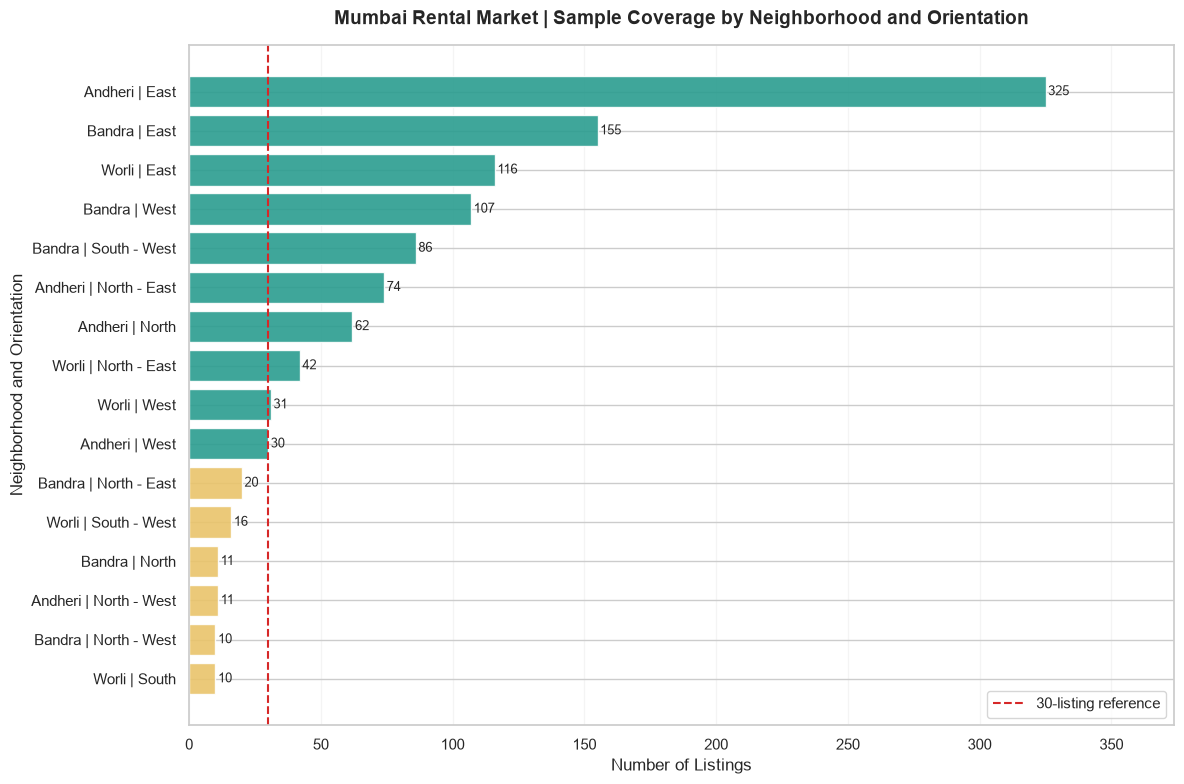

In [67]:
# Create a readable category label
plot_validation = validated_groups.copy()

plot_validation["Group"] = (
    plot_validation["Neighborhood"]
    + " | "
    + plot_validation["Facing_group"]
)

# Sort by sample size
plot_validation = plot_validation.sort_values(
    "Listings", ascending=True
)

# Draw horizontal bars
fig, ax = plt.subplots(figsize=(12, 8))

colors = [
    "#2a9d8f" if n >= 30 else "#e9c46a"
    for n in plot_validation["Listings"]
]

bars = ax.barh(
    plot_validation["Group"],
    plot_validation["Listings"],
    color=colors,
    alpha=0.9
)

# Reference line for stronger sample coverage
ax.axvline(
    30,
    color="#d62828",
    linestyle="--",
    linewidth=1.5,
    label="30-listing reference"
)

# Display exact sample sizes
for bar in bars:
    width = bar.get_width()
    ax.text(
        width + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{int(width)}",
        va="center",
        fontsize=9
    )

ax.set_title(
    "Mumbai Rental Market | Sample Coverage by Neighborhood and Orientation",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Number of Listings")
ax.set_ylabel("Neighborhood and Orientation")
ax.legend()
ax.set_xlim(
    0,
    max(plot_validation["Listings"].max() * 1.15, 35)
)
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()


## Limitations and Future Improvements

### Dataset Limitations

- **Geographic precision:** Neighborhoods were extracted from listing titles rather than verified geographic coordinates.
- **Incomplete information:** Some property attributes contain missing or inconsistent values.
- **Area units:** The precise measurement unit of the reported area should be verified before interpreting rent-per-area values as INR per square foot.
- **Market representativeness:** The dataset may not reflect all rental properties available across Mumbai.
- **Temporal information:** Without reliable listing dates, the analysis cannot establish current market conditions or rental-price trends over time.

### Analytical Limitations

- Median comparisons do not establish causal relationships.
- Differences in building quality, amenities, property age, and micro-location may influence observed prices.
- Small groups can produce unstable median estimates.
- Minimum sample-size thresholds are descriptive safeguards, not statistical significance tests.

### Future Improvements

Future work could include:

1. More accurate neighborhood identification and geographic validation.
2. Statistical modeling to estimate rental prices using multiple property characteristics simultaneously.
3. Cross-validation and error metrics to evaluate predictive performance.
4. Bias and representativeness checks across property categories and neighborhoods.
5. Temporal analysis if reliable listing dates become available.

In [68]:
# 1. Dataset dimensions
total_rows = len(df_final)
total_columns = len(df_final.columns)

# 2. Missing values
missing_count = df_final.isna().sum()
missing_percent = (
    missing_count / total_rows * 100
    if total_rows > 0
    else missing_count.astype(float)
)

# 3. Create quality summary
quality_report = pd.DataFrame({
    "Column": df_final.columns,
    "Missing_Values": missing_count.values,
    "Missing_Percent": missing_percent.values,
    "Data_Type": df_final.dtypes.astype(str).values
})

quality_report = quality_report.sort_values(
    "Missing_Percent",
    ascending=False
)

# 4. Duplicate records
duplicate_rows = df_final.duplicated().sum()

# 5. Key numerical checks
checks = {}

for col in [
    "Price_num",
    "Area_num",
    "BHK_num",
    "Bathrooms_num",
    "Balconies_num"
]:
    if col in df_final.columns:
        values = pd.to_numeric(
            df_final[col],
            errors="coerce"
        )

        checks[col] = {
            "Non_Missing": int(values.notna().sum()),
            "Missing": int(values.isna().sum()),
            "Non_Positive": int(
                (values <= 0).sum()
            ),
            "Minimum": values.min(),
            "Median": values.median(),
            "Maximum": values.max()
        }

# 6. Display report
print("=" * 55)
print("FINAL DATA QUALITY REPORT")
print("=" * 55)

print(f"Total records: {total_rows:,}")
print(f"Total columns: {total_columns}")
print(f"Exact duplicate rows: {duplicate_rows:,}")

print("\nMissing values by column:")
display(quality_report.round(2))

print("\nNumerical variable checks:")
display(pd.DataFrame(checks).T.round(2))

print("\nQuality review completed.")

FINAL DATA QUALITY REPORT
Total records: 18,846
Total columns: 27
Exact duplicate rows: 0

Missing values by column:


,Column,Missing_Values,Missing_Percent,Data_Type
6,Balconies,10323,54.78,float64
24,Balconies_num,10323,54.78,float64
14,Year of Construction,5229,27.75,float64
17,Property Image,2297,12.19,str
7,Floor,737,3.91,float64
23,Bathrooms_num,15,0.08,Float64
4,Bathrooms,15,0.08,float64
5,Furnished,13,0.07,str
25,Furnished_clean,13,0.07,string
0,Title,0,0.00,str



Numerical variable checks:


,Non_Missing,Missing,Non_Positive,Minimum,Median,Maximum
Price_num,18846.0,0.0,0.0,1800.0,70000.0,3800000.0
Area_num,18846.0,0.0,0.0,250.0,1100.0,14500.0
BHK_num,18846.0,0.0,0.0,1.0,2.0,5.0
Bathrooms_num,18831.0,15.0,0.0,1.0,2.0,6.0
Balconies_num,8523.0,10323.0,0.0,1.0,1.0,5.0



Quality review completed.
